#**Analisi Preliminare Fase 0**
1. Attivare il Runtime della GPU e verificare che funzioni.
2. Caricare il dataset MNIST (cercare sulla documentazione come fare) e capirne le caratteristiche, eseguendo anche l'esplorazione del dataset.
3. Modelli Logistic Regression e DenseNet CNN compatibile con il dataset, eseguire i calcoli di parametri e output shape.
4. Allenare la Logistic Regression e la CNN.
5. Testare la CNN e calcolare l'accuracy. <br>

Vedere appunti e codice dei notebook <br>
1. profai_11_XAI_esercizi_05_05_Computer_Vision_Q_mio <br>
2. profai_11_XAI_esercizi_05_05_Computer_Vision_A_tutor

#**TEST FASE 0 CON CLAUDE** <br>

Come eseguirlo

Su Colab con runtime GPU, copia i file nel repository (o fai il commit e poi il clone). Poi:

!git clone https://github.com/francescofrigerio/profai_11_xai_prj_bancavirtuosa
%cd profai_11_xai_prj_bancavirtuosa-main/1_design/fase_0/
!pip -q install captum lime shap scikit-image
%run phase0_checks.py --quick
%run phase0_checks.py

Usa %run e non !python: solo nello stesso kernel il controllo 1 può rilevare se pip ha cambiato pacchetti già caricati e serve riavviare il runtime.

Prima --quick: pesi casuali, dati minuscoli, pochi minuti. Serve a scovare errori nello script.
I risultati non sono validi per le decisioni, e il file prodotto è separato (_quick).

Poi il run completo: l’ordine è 1, 2, 5, 6, 3, 4, 7, 8, 11, 12, 9, 10. Il controllo 6 viene prima di 3, 4, 11 e 12
perché salva la testa addestrata che quei controlli usano. Il controllo 6 con le due varianti è il più lungo.

Cosa mi serve da te
L’output della console del --quick (o gli errori, se ce ne sono), così correggo lo script prima del run completo.

Poi phase0_results.json, phase0_summary.md e le 5 figure phase0_*.png.
Quattro controlli (5, 7, 8, 12) hanno un esito che va giudicato a occhio: sono contrassegnati REVIEW e il riepilogo li elenca.

L’ok sulle correzioni dell’errata ancora in stato P. Quelle che incidono di più sul resto sono E03
(regola di ricampionamento), E07 e E08 (campione e galleria).

Alla chiusura della tappa 0 dimostrerò i criteri concordati:
ogni controllo PASS, oppure FAIL
con una decisione documentata.
 A quel punto parte la tappa 1.


#HOW TO RUN (Google Colab, GPU runtime) : all checks
--------------------------------------

In [ ]:
!pwd

/content


/content
Cloning into 'profai_11_xai_prj_bancavirtuosa'...
remote: Enumerating objects: 112, done.
remote: Counting objects: 100% (112/112), done.
remote: Compressing objects: 100% (77/77), done.
remote: Total 112 (delta 41), reused 83 (delta 23), pack-reused 0 (from 0)
Receiving objects: 100% (112/112), 504.06 KiB | 29.65 MiB/s, done.
Resolving deltas: 100% (41/41), done.
/content/profai_11_xai_prj_bancavirtuosa/1_design/fase_0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 20.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 36.9 MB/s eta 0:00:00

=== CHECK 1: Environment, versions, GPU, no-restart ====================
  [PASS] all required libraries import: torch=2.11.0+cu130, torchvision=0.26.0+cu130, numpy=2.1.3, scipy=1.16.3, scikit-learn=1.6.1, captum=0.9.0, lime=0.2.0.1, shap=0.52.0, scikit-image=0.25.2, matplotlib=3.10.0, pandas=2.2.3, seaborn=0.13.2
  [PASS] no package changed after being loaded 

100%|██████████| 30.8M/30.8M [00:00<00:00, 190MB/s]


  [INFO] in-place ReLU modules in torchvision DenseNet121: 120 (plus the functional F.relu(inplace=True) in forward)
  [INFO] FLAG_RELU_INPLACE=True: the models of the other checks use torchvision's in-place ReLUs
  [PASS] patch removes every in-place ReLU and leaves logits unchanged (max diff 0.00e+00)
  [PASS] gradcam on norm5 (signed): in-place model gives the same map (relative diff 0.0e+00)
  [PASS] integrated gradients: in-place model gives the same map (relative diff 8.4e-07)
  [FAIL] gradient shap (captum): in-place model gives a DIFFERENT map (relative diff 0.56) -> silently wrong explanations
  [PASS] gradient shap (shap): in-place model gives the same map (relative diff 7.7e-08)
  [FAIL] FLAG_RELU_INPLACE=True is NOT safe for: gradient shap (captum). Set FLAG_RELU_INPLACE=False in config (nothing switches by itself).
  [PASS] Grad-CAM on features.norm5: shape (1, 1, 4, 4) (expected (1,1,4,4)), finite, non-negative: True; 19 ms
  [PASS] Grad-CAM on features.denseblock3: shape

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.52MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 130kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.20MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.40MB/s]


  [INFO] sklearn 1.6.1; LR input range [0.0, 1.0], 784 features, not standardized
  [INFO] C=1.0: fit 62.6s, n_iter 248, val acc 0.9222
  [PASS] C=1.0: ConvergenceWarning=False
  [PASS] C=1.0: validation accuracy 0.9222 (design expects ~0.92, range 0.9-0.94)
  [PASS] C=1.0: logit = sum(w*x)+b exactly (max error 0.0e+00)
  [PASS] C=1.0: classes_ == 0..9 (coefficient rows aligned)
  [PASS] C=1.0: per-pixel sum of coefficients over classes max 1.0e-13 (~0 with l2: relative and absolute coefficients coincide)
  [INFO] C=1.0: warning raised -> DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in
  [INFO] C=1.0: warning raised -> DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  figure saved: outputs/phase0/phase0_05_lr_global_maps_C1.0.png


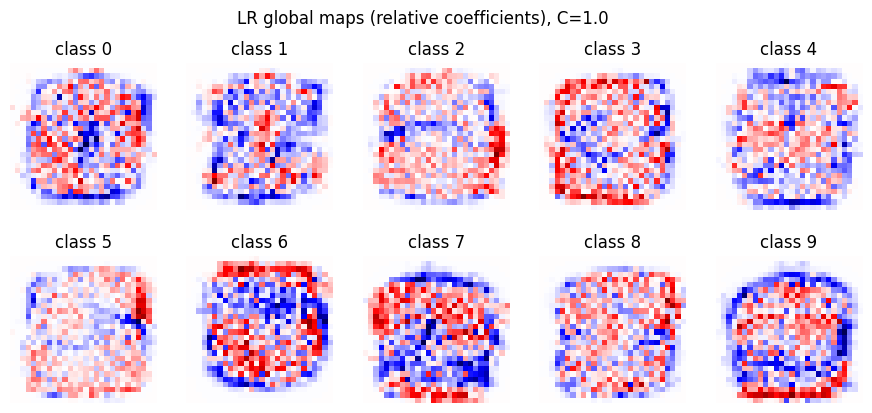

  [REVIEW] look at the phase0_05_lr_global_maps_*.png: are the maps readable (smooth, digit-shaped) at the configured LR_C?
  -> check 5 status: REVIEW (73.2s)

=== CHECK 6: Frozen DenseNet training (time, accuracy, BatchNorm) ====================
  [PASS] tensor preprocessing vs torchvision PIL pipeline: max diff 0.0174, mean 0.00116 (normalized units; uint8 rounding alone is ~0.009)
  [INFO] training CONFIGURED setting: 5 epoch(s), batch 64, lr 0.001, backbone frozen, FLAG_BATCHNORM_EVAL=True, FLAG_RELU_INPLACE=True
    epoch 1: train loss 0.3388 acc 0.9121 | val loss 0.1839 acc 0.9497 | 57s + 7s
    epoch 2: train loss 0.1517 acc 0.9564 | val loss 0.1419 acc 0.9597 | 60s + 8s
    epoch 3: train loss 0.1204 acc 0.9647 | val loss 0.1224 acc 0.9647 | 60s + 8s
    epoch 4: train loss 0.1045 acc 0.9696 | val loss 0.1183 acc 0.9628 | 60s + 7s
    epoch 5: train loss 0.0939 acc 0.9721 | val loss 0.1046 acc 0.9700 | 60s + 7s
  [PASS] trainable parameters: 10250 (expected 10250: the Linear h

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  [PASS] lime/lime: shape (128, 128), finite=True, median 3.0s/img, deterministic=True
  [PASS] lime/captum: shape (128, 128), finite=True, median 1.6s/img, deterministic=True
  [PASS] shap/shap: shape (128, 128), finite=True, median 6.9s/img, deterministic=True
  [PASS] shap/captum: shape (128, 128), finite=True, median 0.5s/img, deterministic=False
  [WARN] shap/captum: same seed gave different maps (max relative diff 6.4e-01; GPU atomics or unseeded randomness)
  figure saved: outputs/phase0/phase0_03_backend_maps.png


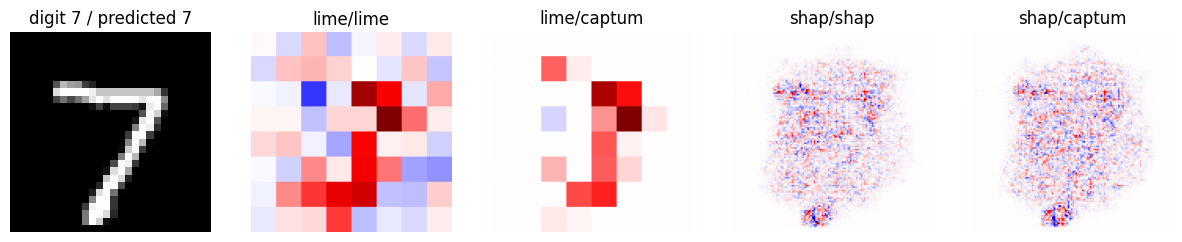

  [REVIEW] look at phase0_03_backend_maps.png: do the maps of both backends of each technique roughly highlight the digit? (meaningful only if check 6 ran first)
  -> check 3 status: WARN (49.1s)

=== CHECK 4: Integrated Gradients (completeness, black baseline) ====================
  [PASS] baseline is black in the original image (max |denormalized| = 3.0e-08); in normalized space it is [-2.118, -2.036, -1.804], NOT zero
  [FAIL] completeness violated: worst relative error 20.269%
  [PASS] attribution is exactly zero wherever the image equals the baseline (background): True
  [INFO] IG median 0.13s/img
  -> check 4 status: FAIL (0.6s)

=== CHECK 7: LIME grid segmentation (visual) ====================
  figure saved: outputs/phase0/phase0_07_lime_grid.png


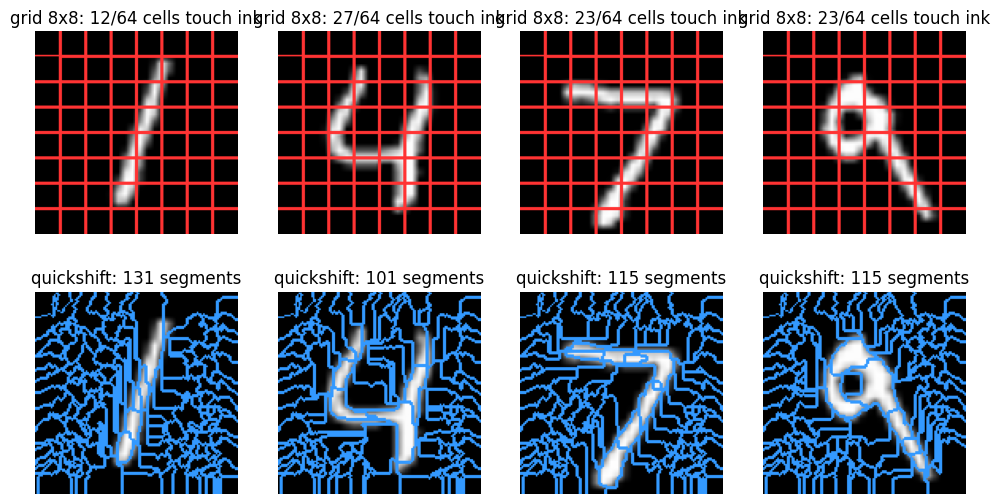

  [INFO] grid cells touching the digit (digits 1,4,7,9): [12, 27, 23, 23]
  [REVIEW] look at phase0_07_lime_grid.png: does the 8x8 grid separate the digit into a useful number of pieces (not 1-2 cells, not the whole image)? and is the quickshift row clearly worse (design D11 says so)? Confirm or change LIME_GRID_CELLS.
  -> check 7 status: REVIEW (1.1s)

=== CHECK 8: Digit mask (visual) ====================
  [INFO] thr=0.05,dil=0: mask covers 17.9% +/- 5.4% of the 784 pixels, empty masks: 0
  [INFO] thr=0.05,dil=1: mask covers 30.5% +/- 7.5% of the 784 pixels, empty masks: 0
  [INFO] thr=0.05,dil=2: mask covers 42.6% +/- 9.4% of the 784 pixels, empty masks: 0
  [INFO] thr=0.1,dil=0: mask covers 17.1% +/- 5.3% of the 784 pixels, empty masks: 0
  [INFO] thr=0.1,dil=1: mask covers 29.8% +/- 7.4% of the 784 pixels, empty masks: 0
  [INFO] thr=0.1,dil=2: mask covers 41.9% +/- 9.3% of the 784 pixels, empty masks: 0
  [INFO] thr=0.2,dil=0: mask covers 15.9% +/- 5.1% of the 784 pixels, empty 

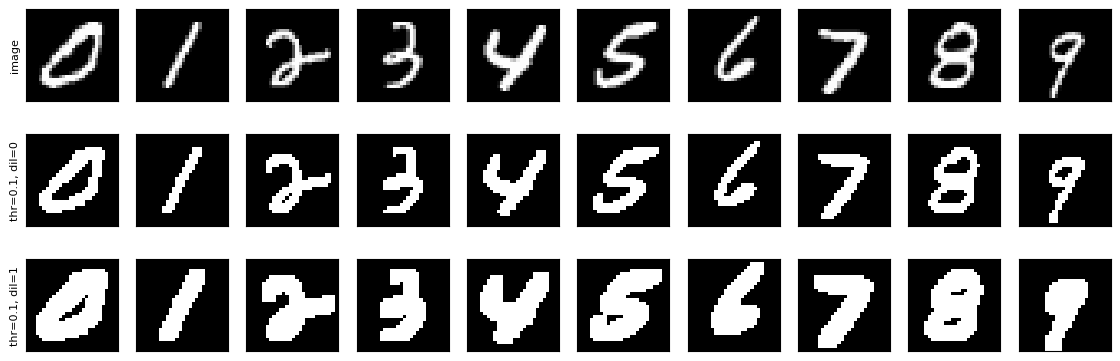

  [REVIEW] look at phase0_08_mask.png: does the dilated mask cover the whole stroke and its immediate halo without swallowing the background? Confirm MASK_THRESHOLD and MASK_DILATION. NOTE: dilation uses a 3x3 square element (8-connected), a detail the design did not specify (errata E17).
  -> check 8 status: REVIEW (1.3s)

=== CHECK 11: Occlusion behaviour (overlap, channels, forwards) ====================
  [INFO] overlapping windows are averaged (distinct values on the toy model: [768.0])
  [PASS] forward images used: 226 (windows expected: 225, +1 for the original image)
  [PASS] windows cover all 3 channels together: channel maps identical (max diff 0.0e+00) -> take the mean over channels
  [PASS] output shape (1, 3, 128, 128), finite
  [INFO] Occlusion 0.35s/img
  -> check 11 status: PASS (0.5s)

=== CHECK 12: Resampling rule to the 28x28 grid ====================
  [PASS] 28 -> 128 -> 28 round trip keeps every test pixel in place: 100/100
  [PASS] each 4x4 Grad-CAM cell peaks in

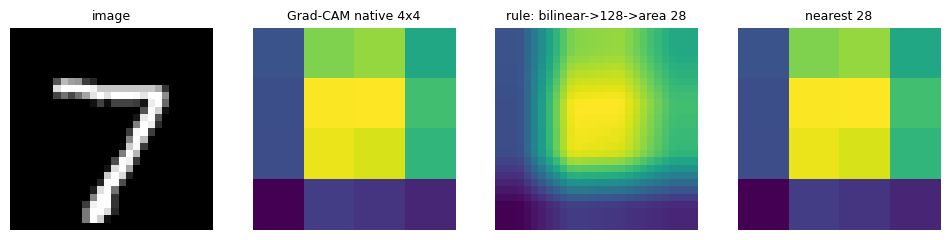

  [REVIEW] look at phase0_12_resampling.png: is the rule's 28x28 map a faithful, smooth version of the native Grad-CAM (and clearly better than blocky nearest)? Confirm the rule (errata E03).
  -> check 12 status: REVIEW (0.3s)

=== CHECK 9: Timings and N_QUANT ====================
  [INFO] seconds per image, all five techniques: 10.4 (LIME backend lime, SHAP backend shap)
  [PASS] N_QUANT = 100: quantitative stage ~17.3 min (budget 20 min)
  [PASS] 'Esegui tutto' with MODEL_MODE=load: ~27 min (limit 30 min)
  [PASS] 'Esegui tutto' with MODEL_MODE=train: ~32 min (limit 45 min)
  [INFO] breakdown: gallery 6.2 min, test inference 0.2 min, fixed overhead 2 min
  -> check 9 status: PASS (0.0s)

=== CHECK 10: Backend decision and table of fixed values ====================

| Parameter | Initial | Proposed | Basis | Confirmation |
|---|---|---|---|---|
| LIME_BACKEND | lime | lime | check 3 | criterion met (automatic) |
| SHAP_BACKEND | shap | shap | check 3 | criterion met (automatic) |
| N

<Figure size 640x480 with 0 Axes>

In [ ]:
# avoid cloning inside an already-cloned folder
%cd /content
!git clone https://github.com/francescofrigerio/profai_11_xai_prj_bancavirtuosa

# wherever config.py and this file live
%cd profai_11_xai_prj_bancavirtuosa/1_design/fase_0

!pip -q install captum lime shap scikit-image

# quick -> ~minutes, random weights, tiny data: catches script bugs
# %run phase0_checks.py --quick
%run phase0_checks.py

#HOW TO RUN (Google Colab, GPU runtime) : checks 2,3,4,13,14

/content
Cloning into 'profai_11_xai_prj_bancavirtuosa'...
remote: Enumerating objects: 144, done.
remote: Counting objects: 100% (144/144), done.
remote: Compressing objects: 100% (99/99), done.
remote: Total 144 (delta 53), reused 110 (delta 30), pack-reused 0 (from 0)
Receiving objects: 100% (144/144), 1.08 MiB | 3.57 MiB/s, done.
Resolving deltas: 100% (53/53), done.
/content/profai_11_xai_prj_bancavirtuosa/1_design/fase_0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 9.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 20.9 MB/s eta 0:00:00
START STEP checks 2,3,4,13,14

=== CHECK 2: In-place ReLU patch and Grad-CAM ====================
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 195MB/s]


  [INFO] in-place ReLU modules in torchvision DenseNet121: 120 (plus the functional F.relu(inplace=True) in forward)
  [INFO] FLAG_RELU_INPLACE=True: the models of the other checks use torchvision's in-place ReLUs
  [PASS] patch removes every in-place ReLU and leaves logits unchanged (max diff 0.00e+00)
  [PASS] gradcam on norm5 (signed): in-place model gives the same map (relative diff 0.0e+00)
  [PASS] integrated gradients: in-place model gives the same map (relative diff 8.5e-07)
  [PASS] saliency: in-place model gives the same map (relative diff 3.5e-07)


/usr/local/lib/python3.13/dist-packages/captum/attr/_core/saliency.py:129: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  gradient_mask = apply_gradient_requirements(inputs_tuple)


  [PASS] gradient shap (captum): in-place model gives the same map (relative diff 1.5e-07)
  [PASS] gradient shap (shap): in-place model gives the same map (relative diff 7.8e-08)
  [PASS] Grad-CAM on features.norm5: shape (1, 1, 4, 4) (expected (1,1,4,4)), finite, non-negative: True; 34 ms
  [PASS] Grad-CAM on features.denseblock3: shape (1, 1, 8, 8) (expected (1,1,8,8)), finite, non-negative: True; 39 ms
  -> check 2 status: PASS (14.4s)

=== CHECK 14: Checkpoint round trip ====================


...

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  [PASS] lime/lime: shape (128, 128), finite=True, median 3.1s/img, deterministic=True
  [PASS] lime/captum: shape (128, 128), finite=True, median 1.5s/img, deterministic=True
  [INFO] lime/captum: constant map (expected with a barely trained quick-run model; suspicious on the real checkpoint)
  [PASS] shap/shap: shape (128, 128), finite=True, median 6.5s/img, deterministic=True
  [PASS] shap/captum: shape (128, 128), finite=True, median 0.5s/img, deterministic=True
  figure saved: outputs/phase0/phase0_03_backend_maps.png


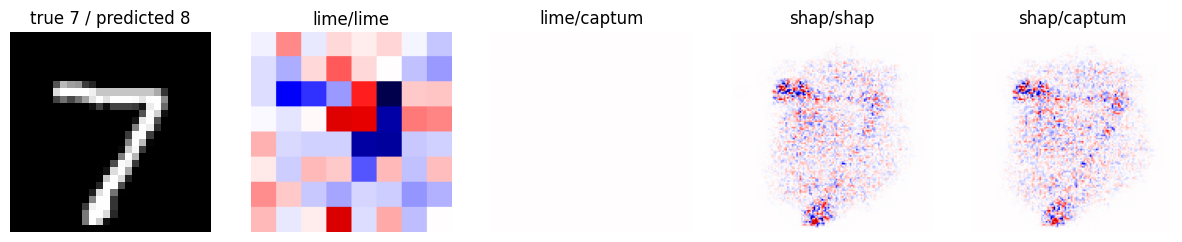

  [REVIEW] look at phase0_03_backend_maps.png: do the maps of both backends of each technique roughly highlight the digit? (meaningful only if check 6 ran first)
  -> check 3 status: REVIEW (47.3s)

=== CHECK 4: Integrated Gradients (completeness, black baseline) ====================
  [PASS] baseline is black in the original image (max |denormalized| = 3.0e-08); in normalized space it is [-2.118, -2.036, -1.804], NOT zero
  [INFO] IG_STEPS=50: worst completeness error 22.85%, 0.20s/img
  [INFO] IG_STEPS=100: worst completeness error 14.62%, 0.32s/img
  [INFO] IG_STEPS=200: worst completeness error 4.54%, 0.54s/img
  [INFO] IG_STEPS=400: worst completeness error 4.42%, 1.00s/img
  [FAIL] completeness violated at IG_STEPS=50: worst error 22.85%
  [INFO] smallest tested IG_STEPS meeting 5%: 200
  [PASS] attribution is exactly zero wherever the image equals the baseline (background)
  -> check 4 status: FAIL (7.3s)

=== CHECK 13: Saliency (candidate sixth technique) ====================


/usr/local/lib/python3.13/dist-packages/captum/attr/_core/saliency.py:129: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  gradient_mask = apply_gradient_requirements(inputs_tuple)


  [PASS] saliency map: shape (S,S), finite, non-negative (abs=True), not all zero
  [PASS] saliency is deterministic: True
  [INFO] saliency 0.041s/img (one backward pass)
  [INFO] share of the attribution falling inside the digit mask (a random map would give the mask area, 22.4%): saliency 22.7%, integrated gradients 100.0%
  [WARN] saliency concentrates on the digit no more than a random map would (expected to be noisy: a result to explain, not a bug)
  [REVIEW] saliency is the noisiest gradient technique: the 7x7 agreement matrices and the gallery would gain a column/row. Operator decision (errata E22).
  -> check 13 status: WARN (0.6s)

SUMMARY
  check  2  PASS    In-place ReLU patch and Grad-CAM  (14.43s)
  check 14  WARN    Checkpoint round trip  (3.53s)
  check  3  REVIEW  LIME and SHAP backends  (47.29s)
  check  4  FAIL    Integrated Gradients (completeness, black baseline)  (7.3s)
  check 13  WARN    Saliency (candidate sixth technique)  (0.61s)

Figures to judge by eye (REV

<Figure size 640x480 with 0 Axes>

In [ ]:
# avoid cloning inside an already-cloned folder
%cd /content
!git clone https://github.com/francescofrigerio/profai_11_xai_prj_bancavirtuosa

# wherever config.py and this file live
%cd profai_11_xai_prj_bancavirtuosa/1_design/fase_0

!pip -q install captum lime shap scikit-image
print("START STEP checks 2,3,4,13,14")
%run phase0_checks.py --checks 2,3,4,13,14
print("END STEP checks 2,3,4,13,14")

#HOW TO RUN (Google Colab, GPU runtime) : checks 6,14,3,4,13 --no-bn-comparison

/content
Cloning into 'profai_11_xai_prj_bancavirtuosa'...
remote: Enumerating objects: 162, done.
remote: Counting objects: 100% (162/162), done.
remote: Compressing objects: 100% (113/113), done.
remote: Total 162 (delta 62), reused 123 (delta 34), pack-reused 0 (from 0)
Receiving objects: 100% (162/162), 1.25 MiB | 14.18 MiB/s, done.
Resolving deltas: 100% (62/62), done.
/content/profai_11_xai_prj_bancavirtuosa/1_design/fase_0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 4.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 15.8 MB/s eta 0:00:00
START STEP checks 6,14,3,4,13 no-bn-comparison 

=== CHECK 6: Frozen DenseNet training (time, accuracy, BatchNorm) ====================


100%|██████████| 9.91M/9.91M [00:00<00:00, 60.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.52MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.8MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.10MB/s]


  [PASS] tensor preprocessing vs torchvision PIL pipeline: max diff 0.0174, mean 0.00116 (normalized units; uint8 rounding alone is ~0.009)
  [INFO] training CONFIGURED setting: 5 epoch(s), batch 64, lr 0.001, backbone frozen, FLAG_BATCHNORM_EVAL=True, FLAG_RELU_INPLACE=True
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 145MB/s]


    epoch 1: train loss 0.3388 acc 0.9121 | val loss 0.1839 acc 0.9497 | 62s + 7s
    epoch 2: train loss 0.1517 acc 0.9564 | val loss 0.1419 acc 0.9597 | 61s + 7s
    epoch 3: train loss 0.1204 acc 0.9647 | val loss 0.1224 acc 0.9647 | 59s + 7s
    epoch 4: train loss 0.1045 acc 0.9696 | val loss 0.1183 acc 0.9628 | 60s + 7s
    epoch 5: train loss 0.0939 acc 0.9721 | val loss 0.1046 acc 0.9700 | 60s + 7s
  [PASS] trainable parameters: 10250 (expected 10250: the Linear head only)
  [PASS] BatchNorm running statistics of the backbone unchanged after training (max drift 0.00e+00)
  [PASS] validation accuracy of the FINAL epoch: 0.9700 vs MIN_VAL_ACCURACY 0.95
  [PASS] validation accuracy from epoch 2 on: 0.9597, 0.9647, 0.9628, 0.9700
  [INFO] time per epoch: train 60s + validation 7s (tensor preprocessing on the GPU)
  [INFO] validation loss still dropping clearly (11.6% last epoch): NUM_EPOCHS could be raised (operator decision)
  [INFO] phase-0 head (final epoch) saved to checkpoints

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  [PASS] lime/lime: shape (128, 128), finite=True, median 3.3s/img, deterministic=True
  [PASS] shap/shap: shape (128, 128), finite=True, median 6.9s/img, deterministic=True
  figure saved: outputs/phase0/phase0_03_backend_maps.png


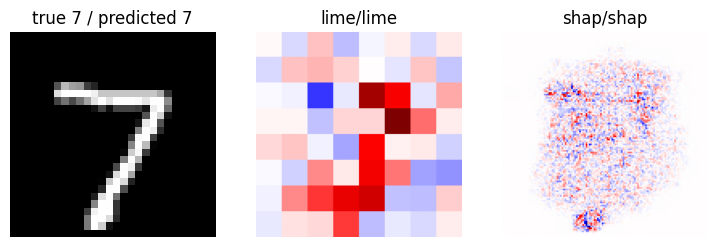

  [REVIEW] look at phase0_03_backend_maps.png: do the maps of both backends of each technique roughly highlight the digit? (meaningful only if check 6 ran first)
  -> check 3 status: REVIEW (43.2s)

=== CHECK 4: Integrated Gradients (completeness, black baseline) ====================
  [PASS] baseline is black in the original image (max |denormalized| = 3.0e-08); in normalized space it is [-2.118, -2.036, -1.804], NOT zero
  [INFO] IG_STEPS=50: worst completeness error 20.27%, 0.13s/img
  [INFO] IG_STEPS=100: worst completeness error 5.14%, 0.26s/img
  [INFO] IG_STEPS=200: worst completeness error 2.99%, 0.53s/img
  [INFO] IG_STEPS=400: worst completeness error 1.59%, 1.07s/img
  [FAIL] completeness violated at IG_STEPS=50: worst error 20.27%
  [INFO] smallest tested IG_STEPS meeting 5%: 200
  [PASS] attribution is exactly zero wherever the image equals the baseline (background)
  -> check 4 status: FAIL (6.7s)

=== CHECK 13: Saliency (candidate sixth technique) ====================
  

<Figure size 640x480 with 0 Axes>

In [ ]:
%cd /content
!git clone https://github.com/francescofrigerio/profai_11_xai_prj_bancavirtuosa
%cd profai_11_xai_prj_bancavirtuosa/1_design/fase_0
!pip -q install captum lime shap scikit-image

print("START STEP checks 6,14,3,4,13 no-bn-comparison ")
%run phase0_checks.py --checks 6,14,3,4,13 --no-bn-comparison
print("END STEP checks 6,14,3,4,13 no-bn-comparison")

#HOW TO RUN (Google Colab, GPU runtime) : all checks **FINAL**

/content
Cloning into 'profai_11_xai_prj_bancavirtuosa'...
remote: Enumerating objects: 173, done.
remote: Counting objects: 100% (173/173), done.
remote: Compressing objects: 100% (124/124), done.
remote: Total 173 (delta 68), reused 128 (delta 34), pack-reused 0 (from 0)
Receiving objects: 100% (173/173), 1.34 MiB | 4.23 MiB/s, done.
Resolving deltas: 100% (68/68), done.
/content/profai_11_xai_prj_bancavirtuosa/1_design/fase_0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 17.7 MB/s eta 0:00:00
START FULL FINAL RUN

=== CHECK 1: Environment, versions, GPU, no-restart ====================
  [PASS] all required libraries import: torch=2.11.0+cu130, torchvision=0.26.0+cu130, numpy=2.1.3, scipy=1.16.3, scikit-learn=1.6.1, captum=0.9.0, lime=0.2.0.1, shap=0.54.1, scikit-image=0.25.2, matplotlib=3.10.0, pandas=2.2.3, seaborn=0.13.2
  [PASS] no package change

100%|██████████| 30.8M/30.8M [00:00<00:00, 194MB/s]


  [INFO] in-place ReLU modules in torchvision DenseNet121: 120 (plus the functional F.relu(inplace=True) in forward)
  [INFO] FLAG_RELU_INPLACE=True: the models of the other checks use torchvision's in-place ReLUs
  [PASS] patch removes every in-place ReLU and leaves logits unchanged (max diff 0.00e+00)
  [PASS] gradcam on norm5 (signed): in-place model gives the same map (relative diff 0.0e+00)
  [PASS] integrated gradients: in-place model gives the same map (relative diff 9.4e-07)
  [PASS] saliency: in-place model gives the same map (relative diff 2.4e-07)
  [PASS] gradient shap (shap package): in-place model gives the same map (relative diff 9.4e-08)
  [PASS] Grad-CAM on features.norm5: shape (1, 1, 4, 4) (expected (1,1,4,4)), finite, non-negative: True; 21 ms
  [PASS] Grad-CAM on features.denseblock3: shape (1, 1, 8, 8) (expected (1,1,8,8)), finite, non-negative: True; 25 ms
  -> check 2 status: PASS (5.2s)

=== CHECK 5: Logistic regression (convergence, accuracy, exactness) ======

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 491kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.57MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.49MB/s]


  [INFO] sklearn 1.6.1; LR input range [0.0, 1.0], 784 features, not standardized
  [INFO] C=1.0: fit 65.3s, n_iter 248, val acc 0.9222
  [PASS] C=1.0: ConvergenceWarning=False
  [PASS] C=1.0: validation accuracy 0.9222 (design expects ~0.92, range 0.9-0.94)
  [PASS] C=1.0: logit = sum(w*x)+b exactly (max error 0.0e+00)
  [PASS] C=1.0: classes_ == 0..9 (coefficient rows aligned)
  [PASS] C=1.0: per-pixel sum of coefficients over classes max 1.0e-13 (~0 with l2: relative and absolute coefficients coincide)
  [INFO] C=1.0: warning raised -> DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in
  [INFO] C=1.0: warning raised -> DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  figure saved: outputs/phase0/phase0_05_lr_global_maps_C1.0.png


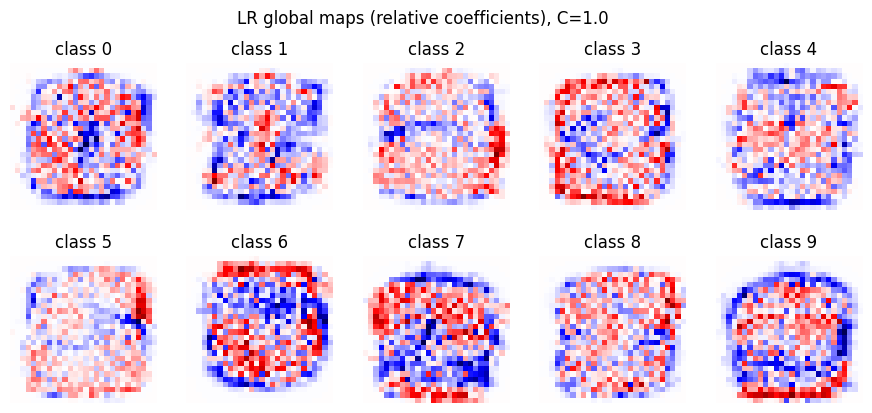

  [REVIEW] look at the phase0_05_lr_global_maps_*.png: are the maps readable (smooth, digit-shaped) at the configured LR_C?
  -> check 5 status: REVIEW (69.7s)

=== CHECK 6: Frozen DenseNet training (time, accuracy, BatchNorm) ====================
  [PASS] tensor preprocessing vs torchvision PIL pipeline: max diff 0.0174, mean 0.00116 (normalized units; uint8 rounding alone is ~0.009)
  [INFO] training CONFIGURED setting: 5 epoch(s), batch 64, lr 0.001, backbone frozen, FLAG_BATCHNORM_EVAL=True, FLAG_RELU_INPLACE=True
    epoch 1: train loss 0.3388 acc 0.9121 | val loss 0.1839 acc 0.9497 | 57s + 7s
    epoch 2: train loss 0.1517 acc 0.9564 | val loss 0.1419 acc 0.9597 | 59s + 7s
    epoch 3: train loss 0.1204 acc 0.9647 | val loss 0.1224 acc 0.9647 | 59s + 7s
    epoch 4: train loss 0.1045 acc 0.9696 | val loss 0.1183 acc 0.9628 | 59s + 7s
    epoch 5: train loss 0.0939 acc 0.9721 | val loss 0.1046 acc 0.9700 | 59s + 7s
  [PASS] trainable parameters: 10250 (expected 10250: the Linear h

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  [PASS] lime/lime: shape (128, 128), finite=True, median 3.2s/img, deterministic=True
  [PASS] shap/shap: shape (128, 128), finite=True, median 6.8s/img, deterministic=True
  figure saved: outputs/phase0/phase0_03_backend_maps.png


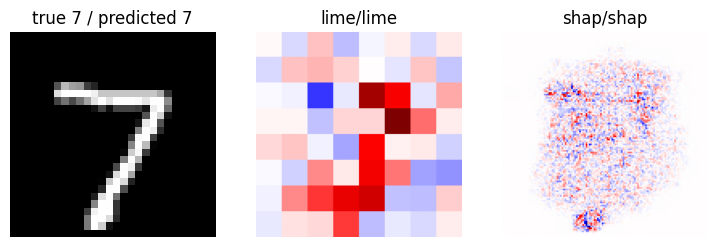

  [REVIEW] look at phase0_03_backend_maps.png: do the maps of both backends of each technique roughly highlight the digit? (meaningful only if check 6 ran first)
  -> check 3 status: REVIEW (40.5s)

=== CHECK 4: Integrated Gradients (completeness, black baseline) ====================
  [PASS] baseline is black in the original image (max |denormalized| = 3.0e-08); in normalized space it is [-2.118, -2.036, -1.804], NOT zero
  [INFO] IG_STEPS=100: worst completeness error 5.14%, 0.25s/img
  [INFO] IG_STEPS=200: worst completeness error 2.99%, 0.52s/img
  [INFO] IG_STEPS=400: worst completeness error 1.59%, 1.05s/img
  [PASS] completeness holds at the configured IG_STEPS=200: worst error 2.99%
  [INFO] smallest tested IG_STEPS meeting 5%: 200
  [PASS] attribution is exactly zero wherever the image equals the baseline (background)
  -> check 4 status: PASS (5.8s)

=== CHECK 13: Saliency (candidate sixth technique) ====================
  [PASS] saliency map: shape (S,S), finite, non-negativ

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  [PASS] lime (1000 samples): seed-to-seed Spearman inside the digit mask 0.85 (per image: 0.83, 0.90, 0.82)
  [PASS] shap (200 samples): seed-to-seed Spearman inside the digit mask 0.80 (per image: 0.87, 0.87, 0.67)
  [PASS] shap (100 samples): seed-to-seed Spearman inside the digit mask 0.78 (per image: 0.84, 0.83, 0.66)
  [INFO] Grad-CAM, IG, Occlusion and Saliency are deterministic: no seed-to-seed variation to measure
  -> check 15 status: PASS (80.4s)

=== CHECK 7: LIME grid segmentation (visual) ====================
  figure saved: outputs/phase0/phase0_07_lime_grid.png


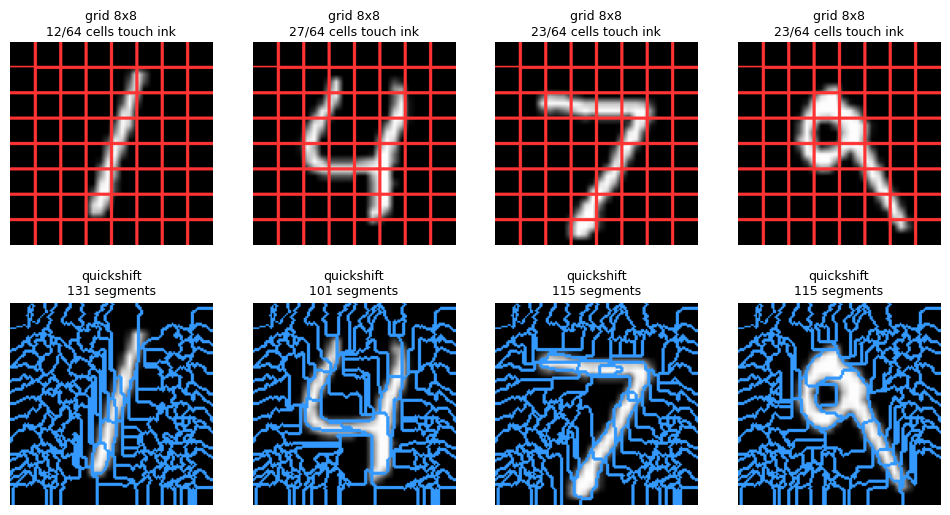

  [INFO] grid cells touching the digit (digits 1,4,7,9): [12, 27, 23, 23]
  [REVIEW] look at phase0_07_lime_grid.png: does the 8x8 grid separate the digit into a useful number of pieces (not 1-2 cells, not the whole image)? and is the quickshift row clearly worse (design D11 says so)? Confirm or change LIME_GRID_CELLS.
  -> check 7 status: REVIEW (1.1s)

=== CHECK 8: Digit mask (visual) ====================
  [INFO] thr=0.05,dil=0: mask covers 17.9% +/- 5.4% of the 784 pixels, empty masks: 0
  [INFO] thr=0.05,dil=1: mask covers 30.5% +/- 7.5% of the 784 pixels, empty masks: 0
  [INFO] thr=0.05,dil=2: mask covers 42.6% +/- 9.4% of the 784 pixels, empty masks: 0
  [INFO] thr=0.1,dil=0: mask covers 17.1% +/- 5.3% of the 784 pixels, empty masks: 0
  [INFO] thr=0.1,dil=1: mask covers 29.8% +/- 7.4% of the 784 pixels, empty masks: 0
  [INFO] thr=0.1,dil=2: mask covers 41.9% +/- 9.3% of the 784 pixels, empty masks: 0
  [INFO] thr=0.2,dil=0: mask covers 15.9% +/- 5.1% of the 784 pixels, empty 

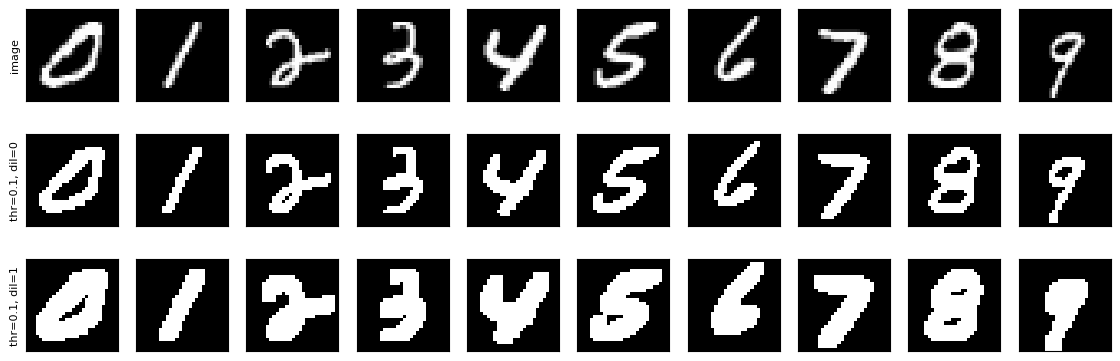

  [REVIEW] look at phase0_08_mask.png: does the dilated mask cover the whole stroke and its immediate halo without swallowing the background? Confirm MASK_THRESHOLD and MASK_DILATION. NOTE: dilation uses a 3x3 square element (8-connected), a detail the design did not specify (errata E17).
  -> check 8 status: REVIEW (1.0s)

=== CHECK 11: Occlusion behaviour (overlap, channels, forwards) ====================
  [INFO] overlapping windows are averaged (distinct values on the toy model: [768.0])
  [PASS] forward images used: 226 (windows expected: 225, +1 for the original image)
  [PASS] windows cover all 3 channels together: channel maps identical (max diff 0.0e+00) -> take the mean over channels
  [PASS] output shape (1, 3, 128, 128), finite
  [INFO] Occlusion 0.33s/img
  -> check 11 status: PASS (0.5s)

=== CHECK 12: Resampling rule to the 28x28 grid ====================
  [PASS] 28 -> 128 -> 28 round trip keeps every test pixel in place: 100/100
  [PASS] each 4x4 Grad-CAM cell peaks in

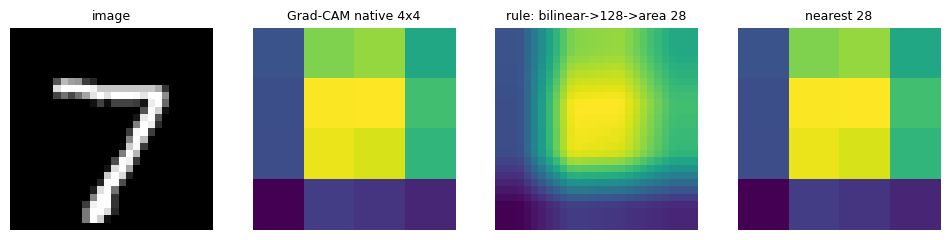

  [REVIEW] look at phase0_12_resampling.png: is the rule's 28x28 map a faithful, smooth version of the native Grad-CAM (and clearly better than blocky nearest)? Confirm the rule (errata E03).
  -> check 12 status: REVIEW (0.3s)

=== CHECK 9: Timings and N_QUANT ====================
  [INFO] seconds per image, all five techniques: 10.9 (LIME backend lime, SHAP backend shap)
  [PASS] N_QUANT = 100: quantitative stage ~18.2 min (budget 20 min)
  [PASS] 'Esegui tutto' with MODEL_MODE=load: ~28 min (limit 30 min)
  [PASS] 'Esegui tutto' with MODEL_MODE=train: ~34 min (limit 45 min)
  [INFO] breakdown: gallery 6.6 min, test inference 0.2 min, fixed overhead 2 min
  -> check 9 status: PASS (0.0s)

=== CHECK 10: Backend decision and table of fixed values ====================

| Parameter | Initial | Proposed | Basis | Confirmation |
|---|---|---|---|---|
| LIME library (E24) | lime | lime | check 3 | criterion met (automatic) |
| SHAP library (E24) | shap | shap | check 3 | criterion met (auto

<Figure size 640x480 with 0 Axes>

In [ ]:
%cd /content
!git clone https://github.com/francescofrigerio/profai_11_xai_prj_bancavirtuosa
%cd profai_11_xai_prj_bancavirtuosa/1_design/fase_0
!pip -q install captum lime shap scikit-image
print("START FULL FINAL RUN")
%run phase0_checks.py
print("END FULL FINAL RUN")

**GIT CLONE DAL REPOSITORY IN PRODUZIONE OPPURE MOUNT DRIVE IN SVILUPPO**

In [ ]:
def run_mount_drive(flag_mount=True):
   """
        Mount Drive for load dataset
   """

   if flag_mount :
      from google.colab import drive
      # drive.mount('/gdrive'
      drive.mount('/content/drive')
      #Colab Notebooks\ProfAi\Corso 09 Generative AI\ProjectCyberEyeSolution
      # %cd drive/MyDrive/'Colab Notebooks'/ProfAi/'Corso 11 ExplainedAi'/ProjectCyberEyeSolution/
      %cd drive/MyDrive/'Colab Notebooks'/ProfAi/'Corso 11 ExplainedAi'/ProjectBancaVirtuosaXai/

   else:
      %cd ProjectBancaVirtuosaXai/
   %ls

run_mount_drive(flag_mount=True)

Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks/ProfAi/Corso 11 ExplainedAi/ProjectBancaVirtuosaXai
data/  models/  output_cnn/  output_cnn_old/  output_lr/  output_lr_old/


In [ ]:
# !ls outputs/phase0
!pwd
!ls

/content/profai_11_xai_prj_bancavirtuosa/1_design/fase_0
appunti_risposta_fase_0_2_3_4_13_14_checks_1.txt
appunti_risposta_fase_0_6_14_3_4_13_nocomparison_checks_2.txt
checkpoints
config_old.py
config.py
data
design_errata.md
design_errata_old.md
models
output_cnn
output_lr
outputs
phase0_checks_old.py
phase0_checks.py
__pycache__
requirements_candidate.txt
requirements.txt
test_config.py


In [ ]:
# !ls outputs/phase0
# !ls /content/profai_11_xai_prj_bancavirtuosa/1_design/fase_0/outputs/phase0/*.*
# !ls ./outputs/phase0/

# !cd /content
# !ls /content/profai_11_xai_prj_bancavirtuosa/1_design/fase_0/outputs/phase0
# !pwd
# !cd /content ; pwd ; ls drive/MyDrive/Colab Notebooks/ProfAi/Corso 11 ExplainedAi/ProjectBancaVirtuosaXai
# !cd /content/drive ; pwd

%cd /content/drive/MyDrive/'Colab Notebooks'/ProfAi/'Corso 11 ExplainedAi'/ProjectBancaVirtuosaXai/output_cnn
# !ls
# !pwd

%cp -r /content/profai_11_xai_prj_bancavirtuosa/1_design/fase_0/outputs/phase0 /content/drive/MyDrive/'Colab Notebooks'/ProfAi/'Corso 11 ExplainedAi'/ProjectBancaVirtuosaXai/output_cnn
!ls phase0

/content/drive/MyDrive/Colab Notebooks/ProfAi/Corso 11 ExplainedAi/ProjectBancaVirtuosaXai/output_cnn
phase0_03_backend_maps.png	   phase0_12_resampling.png
phase0_05_lr_global_maps_C1.0.png  phase0_results.json
phase0_07_lime_grid.png		   phase0_summary.md
phase0_08_mask.png		   requirements_candidate.txt


In [ ]:
!cp /content/profai_11_xai_prj_bancavirtuosa/1_design/fase_0/outputs/phase0/*.* drive/MyDrive/'Colab Notebooks'/ProfAi/'Corso 11 ExplainedAi'/ProjectBancaVirtuosaXai/output_cnn
%ls drive/MyDrive/'Colab Notebooks'/ProfAi/'Corso 11 ExplainedAi'/ProjectBancaVirtuosaXai/output_cnn

phase0_03_backend_maps.png         phase0_12_resampling.png
phase0_05_lr_global_maps_C1.0.png  phase0_results.json
phase0_07_lime_grid.png            phase0_summary.md
phase0_08_mask.png                 requirements_candidate.txt


In [ ]:
# installazione pacchett
!pip -q install captum

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 6.6 MB/s eta 0:00:00


In [ ]:
from tqdm.auto import tqdm
import logging

#DEBUG
# 1. Configurazione di base
# Qui decidiamo il livello minimo (WARNING) e il formato del messaggio
# nel codice con setTrace attivo il debug
logging.basicConfig(
    level=logging.WARNING,
    # level=logging.DEBUG,
    format='%(asctime)s - %(levelname)s - [%(funcName)s] - %(message)s',
    datefmt='%H:%M:%S',
    force=True
)

# Creazione di un oggetto logger
logger = logging.getLogger("AiAppLogger")
logger.setLevel(logging.INFO)


import torch
import torch.nn as nn
import torch.nn.functional as F
import time

# Librera specifica di pytorch per la computer vision
import torchvision
from torch.utils.data import random_split, DataLoader
import torchvision.models as models
from torchvision.models import DenseNet121_Weights, densenet121

# Libreria specfica di pytorch per effettuare trasformazioni
# su tensori che rappresentano delle immagini.
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import Subset
# usata per validare i nostri conti e
# calcolare parametri e dimensioni della rete
# from torchsummary import summary

# Non serve pandas perchè non andiamo a leggere
# il dataset da un csv
import matplotlib.pyplot as plt
import numpy as np
import os
from pathlib import Path

import sys
import random


# Aggiunti rispetto al codice originale
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split


# Altrimenti con la LogisticRegression
# non si vede il warning relativo alla mancata convergenza dopo max_iter
# import warnings
# warnings.filterwarnings('ignore')
import warnings

# 1. Ignora i warning legati alla deprecazione di argomenti nei modelli
warnings.filterwarnings('ignore', category=UserWarning, message=".*pretrained.*")

# 2. Ignora i FutureWarning di librerie terze (es. Pandas o NumPy interni a Torchvision)
warnings.filterwarnings('ignore', category=FutureWarning)
print("Script avviato con warning filtrati in modo selettivo!")


from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
import seaborn as sns


import pandas as pd
from PIL import Image





Script avviato con warning filtrati in modo selettivo!


In [ ]:
# Modelli di Base Saliency e Occlusion
from captum.attr import Saliency, Occlusion
# Modelli Avanzati Integrtared Gradience
from captum.attr import IntegratedGradients

from captum.attr import LayerGradCam

from lime import lime_image
import shap

**1. FUNZIONE DI UTILITA'***

**2. CONFIGURAZIONE E COSTANTI**

**3. RIPRODUCIBILITA'**

**4. CONTROLLO RUNTIME TYPE**


In [ ]:
def sync(device) -> None:
    """
        Syncronizer CPU and GPU to get correct train and val time
        Only Running with CUDA=True
        Run this function before get time to make cpu wait mode until GPU
        has finisched his work.
        Run this function before get time to avoid measure time of previous epoch
    """
    if torch is not None and str(device).startswith("cuda"):
        torch.cuda.synchronize()


def timed(fn, device):
    """
        Wrapper to get time
    """
    sync(device)
    t0 = time.perf_counter()
    out = fn()
    sync(device)
    return out, time.perf_counter() - t0

def set_seed(seed: int) -> None:
    """
        fix seed for every library random,environment,numpy,torch
    """
    os.environ['PYTHONHASHSEED'] = str(SEED)
    random.seed(seed)
    np.random.seed(seed)
    if torch is not None:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)


from dataclasses import dataclass

@dataclass(frozen=True)
class ConfigConstantsDefault:
    """Global config. Replaces magic numbers with descriptive names."""

    # --- Reproducibility and environment
    SEED: int = 42
    # "auto" -> cuda if available, else cpu (warn on cpu)
    DEVICE: str = "auto"

    # --- Data
    # MNIST side (1x28x28): input of the LR baseline
    IMAGE_SIZE: int = 28
    # DenseNet input side (3x128x128)
    DENSENET_SIZE: int = 128
    NUM_CLASSES: int = 10
    # stratified split of the 60k train set
    VAL_SIZE: int = 6000
    # fixed validation images (one per class)
    NUM_DEBUG_IMAGES: int = 10

    # --- Model and training
    CKPT_PATH: str = "./models/checkpoint_fase_0.pt"
    BACKBONE_WEIGHTS: str = "IMAGENET1K_V1"
    # True -> head only, BatchNorm of backbone in eval
    FREEZE_BACKBONE: bool = True
    # warning (not stop) if final validation accuracy is below
    MIN_VAL_ACCURACY: float = 0.95
    NUM_EPOCHS: int = 5
    # to confirm in phase zero
    BATCH_SIZE: int = 64
    # used when FREEZE_BACKBONE=True
    OPTIMIZER: str = "adam"
    LEARNING_RATE_HEAD: float = 1e-3
    # used when FREEZE_BACKBONE=False
    LEARNING_RATE_FULL: float = 5e-5
    # "auto" | "train" | "load"
    MODEL_MODE: str = "auto"
    CHECKPOINT_PATH: str = "checkpoints/densenet121_mnist.pt"
    # BatchNorm of the backbone in eval during training. Effective only when FREEZE_BACKBONE=True
    # (otherwise the backbone trains normally). False reproduces plain model.train().
    FLAG_BATCHNORM_EVAL: bool = True
    # True: keep torchvision's in-place ReLU (less VRAM). False: patch them (non in-place).
    # Nothing switches automatically: if an explanation technique needs False, say so via config.
    FLAG_RELU_INPLACE: bool = True

    # --- Grad-CAM
    GRADCAM_LAYER: str = "features.norm5"
    # for the comparison figure
    GRADCAM_ALT_LAYER: str = "features.denseblock3"
    GRADCAM_DEBUG_EPOCHS: str = "first_last"

    # --- Logistic regression baseline
    LR_PENALTY: str = "l2"
    # optimize and default algoritm based on gradient
    # support L2 regolarize method
    LR_SOLVER: str = "lbfgs"
    # check the power of regolarize.
    # It is inverse value of alpha cioè C = 1 \ alpha .
    # t is the standard trade off between
    # model flexibility and the penalization of complexity.
    LR_C: float = 1.0
    # check ConvergenceWarning in phase zero
    LR_MAX_ITER: int = 1000

    # --- XAI techniques
    LIME_BACKEND: str = "lime"
    SHAP_BACKEND: str = "shap"

    # IG_STEPS: int = 50
    IG_STEPS: int = 200
    # vedere check_11
    OCCLUSION_WINDOW: int = 16
    OCCLUSION_STRIDE: int = 8
    LIME_NUM_SAMPLES: int = 1000
    # 8x8 grid segmentation (to check visually)
    LIME_GRID_CELLS: int = 8
    SHAP_NUM_BACKGROUND: int = 50
     # gradient samples of Gradient SHAP (phase zero)
    # SHAP_NUM_SAMPLES: int = 200
    SHAP_NUM_SAMPLES: int = 100

    # --- Sampling
    GALLERY_SIZE: int = 24
    # quantitative sample; fixed after timing in phase zero
    N_QUANT: int = 100

    # --- Comparison
    # Spearman and IoU
    COMPUTE_AGREEMENT: bool = True
    # "absolute" | "positive"
    SIGN_MODE: str = "absolute"
    # "digit" | "full"
    MASK_MODE: str = "digit"
    # intensity above which a pixel belongs to the digit
    MASK_THRESHOLD: float = 0.1
    MASK_DILATION: int = 1
    TOPK_FRACTION: float = 0.2
    # deletion curves
    COMPUTE_FAITHFULNESS: bool = False
    DELETION_STEPS: int = 10

    # --- Execution and outputs
    RUN_TESTS: bool = False
    OUTPUT_DIR: str = "outputs"
    IN_NOTEBOOK = "ipykernel" in sys.modules



CONFIG = ConfigConstantsDefault()

THRESHOLDS = {
    "backend_max_seconds_per_image": 15.0,    # LIME / SHAP backend accepted if <= (T4)
    "quant_stage_max_minutes": 20.0,          # time budget of the quantitative stage
    "run_all_load_max_minutes": 30.0,         # "Esegui tutto" with MODEL_MODE=load
    "run_all_train_max_minutes": 45.0,        # "Esegui tutto" with MODEL_MODE=train
    "ig_completeness_pass_rel": 0.05,         # |sum(attr) - (f(x)-f(b))| / |f(x)-f(b)|
    "ig_completeness_warn_rel": 0.20,
    "logits_patch_atol": 1e-4,                # logits before/after the ReLU patch
    "preproc_max_abs_diff": 0.05,             # tensor path vs torchvision PIL path (normalized units)
    "lr_expected_acc_range": (0.90, 0.94),    # design expects ~92 %
    "lr_colsum_warn": 1e-3,                   # sum over classes of LR coefficients, per pixel
    "loss_still_dropping_rel": 0.05,          # last-epoch relative val-loss drop => "still dropping"
    "mask_fraction_range": (0.05, 0.60),      # sane share of pixels in the digit mask
    "determinism_rtol": 1e-3,
}

# Random seed for reproducibility




# SEED = 42
SEED = CONFIG.SEED
set_seed(SEED)


# BATCH_SIZE=32
BATCH_SIZE=CONFIG.BATCH_SIZE

print(torch.cuda.is_available())
# settiamo 'cuda' per la GPU altrimenti verra settata la 'cpu'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
print(CONFIG.IN_NOTEBOOK)
# !ls ./models/checkpoint_fase_0.pt
!ls ./models


False
cpu
True
checkpoint_fase_0_old.pt  checkpoint_fase_0.pt


### Modello
- DenseNet121 con pesi `IMAGENET1K_V1`; `classifier` sostituito da `Linear(1024, 10)`.
- **ReLU in-place:** i blocchi usano `ReLU(inplace=True)` e il `forward` finale usa `F.relu(..., inplace=True)` in forma funzionale. Questo rompe gli hook di Grad-CAM e il backward di Captum/SHAP. Va gestito (moduli a `inplace=False`; per il `forward` finale un wrapper sottile). **Da verificare in fase zero.**
- `FREEZE_BACKBONE=True`: `requires_grad=False` su `features`; l'ottimizzatore riceve solo i parametri del `classifier`; **le BatchNorm del backbone restano in `eval`**.

### Perché le BatchNorm in eval
`requires_grad=False` ferma l'aggiornamento dei **pesi**, ma non quello delle **statistiche** (`running_mean`, `running_var`) delle BatchNorm, che in modalità `train()` si aggiornano a ogni batch. MNIST è molto diverso da ImageNet (sfondo quasi tutto nero), quindi le statistiche si sposterebbero e le feature "congelate" cambierebbero senza che nessun peso sia stato modificato. `model.train()` rimette tutti i moduli in train, quindi il freeze va **riapplicato a ogni inizio di epoca** (anche dopo la validation).



**FUNCTION PLOT GRAPH AND IMAGES** <br>

In [ ]:
# funzione per convertire un'immagine da tensore ad un formato visualizzabile
def back_to_image_05(img):
    # DeNormalizzazione
    # faccio l'operazione inversa della normalizzazione
    # domanda su ProfAi
    img = img / 2 + 0.5
    # trasformo in un vettore numpy
    npimg = img.numpy()
    # print("npimg",type(npimg))
    # Facciamo una trasposta perchè , per poter essere
    # visualizzati i canali devono essere all'ultimo posto
    # Non avremo più un tensore ma una matrice numpy
    # avente shape 28x28x1

    # La funzione squeeze di NumPy viene utilizzata per rimuovere le dimensioni
    # di un array che hanno una dimensione pari a 1. In altre parole, "squeeze"
    # elimina le dimensioni singolari di un array, riducendo il numero di dimensioni
    # senza perdere dati.
    # return img.squeeze() # -> soluzione del tutor
    return np.transpose(npimg, (1, 2, 0)) # soluzione esercizio il risultato è lo stesso



def imshow(img):
    """
        Trasformazione inversa dell'immagine nello spazio dei colori.
        Faccio una trasposta nello spazio dei colori altrimenti
        l'immagine non avrà il colore corretto.
        la normalizzazione è diversa da quella sul dataset
        ma influisce solo sulla visualizzazione
    """

    # Definizione dei valori ImageNet per i 3 canali RGB
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    # img = img / 2 + 0.5     # unnormalize
    # print(f"type {type(img)} ")
    # print(f"img {img.shape} ")
    # img = (img * std) + mean # unnormalize
    # npimg = img.numpy()
    # plt.imshow(np.transpose(npimg, (1, 2, 0)))

    # Se il tensore è su GPU, lo portiamo su CPU prima di convertirlo in NumPy
    if isinstance(img, torch.Tensor):
        img = img.cpu().detach().numpy()

    # 1. Portiamo i canali alla fine: (C, H, W) -> (H, W, C)
    # Esempio: da (3, 128, 128) diventa (128, 128, 3)
    npimg = np.transpose(img, (1, 2, 0))
    # 2. Denormalizzazione corretta: x = (y * std) + mean
    # NumPy applica automaticamente l'operazione su ogni canale lungo l'ultimo asse
    npimg = (npimg * std) + mean
    plt.imshow(npimg)



    plt.show()


def back_to_image(img):
    # Definizione dei valori ImageNet per i 3 canali RGB
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    # Se il tensore è su GPU, lo portiamo su CPU prima di convertirlo in NumPy
    if isinstance(img, torch.Tensor):
        img = img.cpu().detach().numpy()

    # 1. Portiamo i canali alla fine: (C, H, W) -> (H, W, C)
    # Esempio: da (3, 128, 128) diventa (128, 128, 3)
    npimg = np.transpose(img, (1, 2, 0))

    # 2. Denormalizzazione corretta: x = (y * std) + mean
    # NumPy applica automaticamente l'operazione su ogni canale lungo l'ultimo asse
    npimg = (npimg * std) + mean

    # 3. Clip per evitare che imprecisioni nei float uscano dal range valido [0, 1] per matplotlib
    npimg = np.clip(npimg, 0, 1)

    return npimg


# Funzione per visualizzare la matrice di confusione
def plot_confusion_matrix_lr(model,X,y_true, title , str_train_test,cfg):
    """
         Plot Confusion Matrix Table
    """

    y_pred =  model.predict(X)
    cm = confusion_matrix(y_true,y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.xlabel('Predicted ' + str_train_test)
    plt.ylabel('True ' + str_train_test)
    plt.title(title + str_train_test)

    report = classification_report(y_true,y_pred, target_names=[str(i) for i in range(cfg.NUM_CLASSES)],digits=4)
    print(report)


def save_fig(fig, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=110, bbox_inches="tight")
    print(f"  figure saved: {path}")
    plt.show() if CONFIG.IN_NOTEBOOK else plt.close(fig)









**FUNCTION LOAD AND PREPROCESSING DATASET** <br>


In [ ]:
def load_dataset_lr():

    transform_lr = transforms.Compose([ transforms.Grayscale(num_output_channels=1),
                                    # Converti in tensore
                                    transforms.ToTensor(),
                                  ])

    mnist_trainvalset_lr = datasets.MNIST(root='./data', train=True, download=True, transform=transform_lr)
    mnist_testset_lr = datasets.MNIST(root='./data', train=False, download=False, transform=transform_lr)

    return mnist_trainvalset_lr,mnist_testset_lr

def load_dataset_cnn():
    # Prendo immagini a caso e le visualizzo
    transform_densenet = transforms.Compose([ # Aumenta altezza e larghezza delle immagini
                                     transforms.Resize((128, 128)),
                                     # Converti in tensore
                                     transforms.ToTensor(),
                                    # espando i canali da 1 a 3
                                    transforms.Lambda(lambda x: x.repeat(3, 1, 1) if x.shape[0] == 1 else x), # Espande a 3 canali
                                    # normalizzazione delle img
                                    transforms.Normalize(
                                    mean=   [0.485, 0.456, 0.406],
                                    std=[0.229, 0.224, 0.225]
                                    )
                                    ])

    mnist_trainvalset_cnn = datasets.MNIST(root='./data', train=True, download=True, transform=transform_densenet)
    mnist_testset_cnn = datasets.MNIST(root='./data', train=False, download=False, transform=transform_densenet)

    return mnist_trainvalset_cnn,mnist_testset_cnn

def split_dataset(trainvalset ,train_size = 54000,val_size = 6000):


    # (Funziona per i dataset Torch standard come MNIST)
    targets = trainvalset.targets

    # Calcoliamo la frazione di validazione desiderata (es. 6000 su 54000 = ~11.1%)
    val_fraction = val_size / (train_size + val_size)

    # 2. Otteniamo gli indici stratificati per train e validation
    # stratify=targets: Dice a scikit-learn di mantenere la stessa identica percentuale di ogni classe (da '0' a '9') sia in train_indices che in val_indices.

    train_indices, val_indices = train_test_split( range(len(trainvalset)),
                                                    test_size=val_fraction,
                                                    # stratificazione!
                                                    stratify=targets,
                                                    random_state=SEED
                                                   )

    # 3. Creiamo i Subset di PyTorch usando gli indici stratificati
    train_dataset = Subset(trainvalset, train_indices)
    val_dataset = Subset(trainvalset, val_indices)

    return train_dataset,val_dataset

def dataloader_to_tensor( dataloader_ , channels , w , h ):

    # Alloco i tensori 1, 28, 28
    # Dove sono allocati sulla GPU o la CPU ?
    X = torch.empty((len(dataloader_.dataset),  channels , w , h),
                dtype=torch.float32)
    y = torch.empty((len(dataloader_.dataset),),
                dtype=torch.int64)

    start = 0
    for images, labels in dataloader_:
        # images ha forma (64, 3, 128, 128) -> il tuo X
        # labels ha forma (64,)             -> il tuo y
        n = images.size(0)

        X[start:start+n].copy_(images)
        y[start:start+n].copy_(labels)

        start += n

    logger.debug(" X " , X.shape)
    logger.debug(" y " , y.shape)
    return X , y

def get_images_labels(dataset_,flag_data_loader=True,idx_dataset=0):

    if flag_data_loader:
        # sola volta in tutto il codice
        dataloader = DataLoader(dataset_, batch_size=32, shuffle=True)
        print(len(dataset_), "immagini,", len(dataset_.class_to_idx), "identità")
        dataiter = iter(dataloader)
        # i valori di images e labels sono tensori di pytorch
        images_, labels_ = next(dataiter)
    else:
        image, label = dataset_[idx_dataset]
        # images_ = [image]
        # labels_ = [label]
        # torch.stack() prende in input una lista di tensori e li impila lungo una nuova dimensione.
        images_ = torch.stack([image])
        # costruisce un nuovo tensore a partire da un valore (o lista di valori) Python nativi
        labels_ = torch.tensor([label])
    return images_, labels_


def load_data_lr():
    """
        load and process data for Logistic Regression
    """
    trainval_dataset_lr , test_dataset_lr = load_dataset_lr()
    train_size = len(trainval_dataset_lr) - CONFIG.VAL_SIZE
    val_size = CONFIG.VAL_SIZE

    logger.debug(f" train_size {train_size}")
    logger.debug(f" val_size {val_size}")

    train_dataset_lr , val_dataset_lr = split_dataset(trainval_dataset_lr ,train_size = train_size,val_size = val_size)

    train_loader_lr = DataLoader(train_dataset_lr, batch_size=BATCH_SIZE,shuffle=True)
    val_loader_lr = DataLoader(val_dataset_lr, batch_size=BATCH_SIZE,shuffle=False)
    test_loader_lr = DataLoader(test_dataset_lr, batch_size=BATCH_SIZE,shuffle=False)

    # Carico i tensori di train e test
    X_train , y_train = dataloader_to_tensor(train_loader_lr,1, CONFIG.IMAGE_SIZE, CONFIG.IMAGE_SIZE)
    X_val , y_val = dataloader_to_tensor(val_loader_lr,1, CONFIG.IMAGE_SIZE, CONFIG.IMAGE_SIZE)
    X_test , y_test = dataloader_to_tensor(test_loader_lr,1, CONFIG.IMAGE_SIZE, CONFIG.IMAGE_SIZE)

    # appiattisco i tensori
    X_train = X_train.reshape(X_train.shape[0], -1)
    X_val = X_val.reshape(X_val.shape[0], -1)
    X_test = X_test.reshape(X_test.shape[0], -1)

    logger.debug(f" X_train flat {X_train.shape}")
    logger.debug(f" X_val flat {X_val.shape}")
    logger.debug(f" X_test flat {X_test.shape}")

    # Converto il tensore nel formato numpy preferito da LogisticRegression
    X_train = X_train.numpy()
    X_val = X_val.numpy()
    X_test = X_test.numpy()
    return  X_train,X_val, X_test,  y_train ,y_val, y_test


**FUNZIONE SPECIFICHE PER LA REGRESSIONE LOGISTICA**

In [ ]:
def plot_logistic_graph(model_,config , out_dir , c ):
    out_dir_path = Path(out_dir)  # Converte la stringa in Path

    # The matrix model_.coef_ has the next shape [10 ,784]:
    # so 10 classes = digits and 784 pixels for every classes
    # Every element is a coefficient w  learned from model.
    # The model use these coefficients to get the score for each classes.

    # È la differenza tra il coefficiente di ciascuna classe
    # e la media dei coefficienti dello stesso pixel calcolata su tutte le classi.
    # Per mettere in evidenza ciò che distingue una classe dalle altre,
    # anziché mostrare semplicemente il coefficiente originale.
    # Un valore positivo indica un coefficiente superiore alla media delle classi per quel pixel;
    # un valore negativo indica un coefficiente inferiore.
    rel = model_.coef_ - model_.coef_.mean(axis=0, keepdims=True)

    # 2d-matrix with single graph
    # axes[0,0], axes[0,1], ..., axes[0,4],
    # axes[1,0], axes[1,1], ..., axes[1,4]
    fig, axes = plt.subplots(2, 5, figsize=(11, 4.6))

    # axes.ravel() convert 2d-matrix in a 1d-array , reading
    # elements from left to right from top to bottom .
    # loop1: k = 0 e ax is the first graph at top left side
    # loop2: k = 1 e ax is the second graph and so on .
    for k, ax in enumerate(axes.ravel()):

        # rel[k] seleziona tutti i coefficienti relativi della classe k: nel nostro esempio, 784 valori=pixels.
        # np.abs(rel[k]) calcola il valore assoluto di ciascun coefficiente. Per esempio, -0.7 diventa 0.7.
        # .max() trova il valore assoluto più grande tra tutti i pixel di quella classe.
        a = max(np.abs(rel[k]).max(), 1e-12)

        # Con reshape i pixel da 1d-array sono disposti in a 2d matrix,
        # che può essere rappresentata come un'immagine.
        ax.imshow(rel[k].reshape(config.IMAGE_SIZE, config.IMAGE_SIZE), cmap="seismic", vmin=-a, vmax=a)
        ax.set_title(f"class {k}")
        ax.axis("off")

    fig.suptitle(f"LR global maps (relative coefficients), C={c}")
    save_fig(fig, out_dir_path / f"phase0_lr_global_maps.png")

def lr_analyze(diag, cfg):
    """
        print result and score about Logistic Regression.
    """
    tag = "LogisticRegression"
    lo, hi = THRESHOLDS["lr_expected_acc_range"]

    logger.info( f"{tag}: fit {diag['fit_seconds']:.1f}s, "
           f"n_iter {diag['n_iter']}, "
           f"val acc {diag['val_accuracy']:.4f}"
         )

    # 1. Convergence
    if diag["convergence_warning"]:
        logger.info(
            f"[WARN] {tag}: ConvergenceWarning=True -> "
            f"consider raising LR_MAX_ITER (now {cfg.LR_MAX_ITER})"
        )
    else:
        logger.info(f"[OK] {tag}: ConvergenceWarning=False")

    # 2. Validation accuracy
    acc = diag["val_accuracy"]
    if lo <= acc <= hi:
        logger.info(
            f"[OK] {tag}: validation accuracy {acc:.4f} "
            f"(expected ~0.92, range {lo}-{hi})"
        )
    else:
        logger.info(
            f"[WARN] {tag}: validation accuracy {acc:.4f} "
            f"(expected ~0.92, range {lo}-{hi})"
        )

    # 3. Verifica della decision function
    err = diag["decision_exact_max_err"]
    if err < 1e-8:
        logger.info(
            f"[OK] {tag}: logit = sum(w*x)+b exactly "
            f"(max error {err:.1e})"
        )
    else:
        logger.info(
            f"[FAIL] {tag}: logit mismatch "
            f"(max error {err:.1e})"
        )

    # 4. Classi
    if diag["classes_ok"]:
        logger.info(f"[OK] {tag}: classes_ == 0..9 (coefficient rows aligned)")
    else:
        logger.info(f"[FAIL] {tag}: classes_ are not aligned with 0..9")

    # 5. Somma dei coefficienti per pixel
    colsum = diag["coef_colsum_max"]
    if colsum <= THRESHOLDS["lr_colsum_warn"]:
        logger.info(
            f"[OK] {tag}: per-pixel sum of coefficients over classes "
            f"max {colsum:.1e} "
            "(~0 with L2: relative and absolute coefficients coincide)"
        )
    else:
        logger.info(
            f"[WARN] {tag}: per-pixel sum of coefficients over classes "
            f"max {colsum:.1e}"
        )

    # 6. Altri warning
    for warning in diag["other_warnings"]:
        logger.info(f"[INFO] {tag}: warning raised -> {warning}")

def lr_fit_and_diagnose(X_train_, y_train_, X_val_, y_val_ , cfg) -> tuple:
    """Fit the LR and measure everything check 5 needs. Returns (model, diagnostics)."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        t0 = time.time()
        model = LogisticRegression(random_state=SEED,max_iter=cfg.LR_MAX_ITER).fit(X_train_, y_train_)
        fit_seconds = time.time() - t0

    categories = sorted({w.category.__name__ for w in caught})
    manual = X_val_ @ model.coef_.T + model.intercept_
    diag = {
        "fit_seconds": fit_seconds,
        "n_iter": int(np.max(model.n_iter_)),
        "convergence_warning": "ConvergenceWarning" in categories,
        "other_warnings": sorted({f"{w.category.__name__}: {str(w.message)[:140]}"
                                  for w in caught if w.category.__name__ != "ConvergenceWarning"}),
        "val_accuracy": float(model.score(X_val_, y_val_)),
        "coef_colsum_max": float(np.abs(model.coef_.sum(axis=0)).max()),
        "decision_exact_max_err": float(np.abs(manual - model.decision_function(X_val_)).max()),
        "classes_ok": bool(np.array_equal(model.classes_, np.arange(cfg.NUM_CLASSES))),
    }
    return model, diag



def run_train_lr():
    """
        Train Regressione Logistica
    """

    X_train ,X_val, X_test , y_train ,y_val ,  y_test = load_data_lr()
    logger.debug(f" X_train numpy {X_train.shape}")
    logger.debug(f" X_test numpy {X_test.shape}")

    # lr = LogisticRegression( random_state=SEED,max_iter=max_iter)
    lr , diag = lr_fit_and_diagnose(X_train, y_train, X_val, y_val ,CONFIG)

    # Calcolo dell'accuratezza di addestramento e test per la Logistic Regression
    test_accuracy_lr = accuracy_score(y_test, lr.predict(X_test))
    logger.info(f"Accuratezza di test (Logistic Regression): {test_accuracy_lr}")

    lr_analyze(diag,CONFIG)

    OUT_DIR="./output_lr"
    plot_logistic_graph(lr, CONFIG, OUT_DIR, c=CONFIG.LR_C)

    # stampo solo la confusion matrix sul test
    # plot_confusion_matrix(lr,X_train,y_train, "CLASSIFIER LR ON MNIST DATASET " , "TRAIN")
    plot_confusion_matrix_lr(lr,X_test,y_test, "CLASSIFIER LR ON MNIST DATASET " , "TEST",CONFIG)

**FUNZIONE SPECIFICHE PER LA CNN**

In [ ]:
def set_batchnorm_eval(module: nn.Module) -> None:
    """Keep BatchNorm running statistics frozen (specification of the design)."""
    if isinstance(module, nn.modules.batchnorm._BatchNorm):
        module.eval()


def enter_train_mode(model: nn.Module, config) -> None:
    """Single entry point to put the model in training mode. Call at the start of EVERY epoch."""
    model.train()
    if config.FREEZE_BACKBONE and CONFIG.FLAG_BATCHNORM_EVAL:
        model.features.apply(set_batchnorm_eval)


def check_model_params(model):
    """
         Check on model params
    """
    # Controlli sui parametri
    total_params = sum(p.numel() for p in model.parameters())

    trainable_params = sum(p.numel() for p in model.parameters()
        if p.requires_grad)

    logger.info(f"[build_densenet] Parametri totali: {total_params:,}")
    logger.info(f"[build_densenet] Parametri congelati: {total_params - trainable_params:,}")
    logger.info(f"[build_densenet] Parametri addestrabili: {trainable_params:,}")

    # for name, param in model.named_parameters():
    #    if param.requires_grad:
    #        logger.info(f"{name} , {param.shape}")


def set_relu_inplace(module):
    """
         Apply modify to input model
         set_relu_inplace(model)
    """
    for name, child in module.named_children():
        if isinstance(child, nn.ReLU):
            # Sostituisce il layer ReLU esistente con uno in-place
            setattr(module, name, nn.ReLU(inplace=True))
        else:
            # Scende nei sottoblocchi (es. nei DenseBlock di DenseNet)
            set_relu_inplace(child)




#  model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
def build_densenet(cfg):
    """
         Build Model , optimizer and define loss Function
    """
    # weights = getattr(DenseNet121_Weights, CONFIG.BACKBONE_WEIGHTS) if pretrained else None
    # model = densenet121(weights=weights)
    # model.classifier = nn.Linear(base.classifier.in_features, cfg.NUM_CLASSES)

    # codice standard senza scaricare da github
    model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)

    # permette di risparmiare memoria VRAM
    set_batchnorm_eval(model)

    for param in model.parameters():
         param.requires_grad = False

    # Modifica dell'ultimo layer per il numero corretto di classi
    # num_classes = len(trainval_dataset_cnn.class_to_idx)
    model.classifier = nn.Linear(model.classifier.in_features, cfg.NUM_CLASSES)

    check_model_params(model)

    loss_function = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    return model,optimizer,loss_function

def get_model(cfg):
    """Eval-mode model (in-place or patched ReLU, per FLAG_RELU_INPLACE).
    """
    model_base , optimizer,loss_function = build_densenet(cfg)
    # trained = cfg.CKPT_PATH.exists()
    trained = Path(cfg.CKPT_PATH).exists()
    if trained:
        # model_base.load_state_dict(torch.load(cfg.CKPT_PATH, map_location="cpu")["state_dict"])
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

        # Carichi il dizionario del checkpoint
        checkpoint = torch.load(cfg.CKPT_PATH, map_location=device)

        # Ripristini lo stato di modello ed ottimizzatore
        model_base.load_state_dict(checkpoint['model_state_dict'])
        model_base.to(device)

        check_model_params(model_base)
        logger.info("  NOTE: yes checkpoint found ")
    else:
        logger.info("  NOTE: no checkpoint found ")

    # for p in model_base.parameters():
    #    p.requires_grad_(False)

    return model_base,optimizer,loss_function

def save_model(cfg,model,optimizer, num_epochs):
    """
    """
    # logger.info(f"{type(loss_cnn)}")
    checkpoint_start = { 'epoch': num_epochs,                            # Epoca corrente
                         'model_state_dict': model.state_dict(),     # Pesi del modello
                         'optimizer_state_dict': optimizer.state_dict() # Stato dell'ottimizzatore (es. momentum, learning rate)
                         # 'loss': loss_cnn,                       # Ultimo valore di loss
                        }

    # trained = cfg.CKPT_PATH.exists()
    trained = Path(cfg.CKPT_PATH).exists()
    if trained == False :
        # Save dict into a file
        # torch.save(checkpoint_start, 'checkpoint_fase_0.pt')
        torch.save(checkpoint_start, cfg.CKPT_PATH)
        logger.info("Checkpoint iniziale salvato con successo!")

# Funzione per visualizzare la matrice di confusione
def plot_confusion_matrix_cnn(y_true_,y_pred_, title , str_train_test,cfg):
    """
         Plot Confusion Matrix Table
    """

    cm = confusion_matrix(y_true_, y_pred_)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.xlabel('Predicted ' + str_train_test)
    plt.ylabel('True ' + str_train_test)
    plt.title(title + str_train_test)

    report = classification_report(y_true_,y_pred_, target_names=[str(i) for i in range(cfg.NUM_CLASSES)],digits=4)
    print(report)

def run_train_cnn(model_ ,
                  dataset_,
                  dataloader_train_ ,
                  dataloader_val_ ,
                  device_ ,
                  optimizer_ ,
                  criterion_ ,
                  num_epochs_=1):

    model_ = model_.to(device_)

    # Training loop
    for epoch in range(num_epochs_):
        # model_.train()
        enter_train_mode(model_,CONFIG)
        running_loss = 0.0
        sync(device)
        t0 = time.time()
        for i, (inputs, labels) in enumerate(dataloader_train_):
            inputs, labels = inputs.to(device_), labels.to(device_)

            optimizer_.zero_grad()
            outputs = model_(inputs)
            loss = criterion_(outputs, labels)
            loss.backward()
            optimizer_.step()

            running_loss += loss.item()
            if i % 1000 == 900:    # stampa ogni 100 mini-batch
                logger.info(f'[Epoca {epoch + 1}, Ciclo {i + 1:5d}] Loss: {running_loss / 10:.3f}')
                running_loss = 0.0
                # break

        sync(device)
        train_seconds = time.time() - t0
        t1 = time.time()

        # CICLO VALIDATION
        y_pred,y_true,y_pred_desc,y_true_desc = run_test_cnn(model_,
                                                             dataset_,
                                                             dataloader_val_,
                                                             device_)
        val_accuracy_cnn = accuracy_score(y_true,y_pred)
        if ( val_accuracy_cnn < CONFIG.MIN_VAL_ACCURACY ):
            logger.info(f"ATTENZIONE!! Accuratezza(DenseNet Cnn) Non Supera la Soglia({CONFIG.MIN_VAL_ACCURACY}): {val_accuracy_cnn}")

        sync(device)
        val_seconds = time.time() - t1
        logger.info(f'[Epoca {epoch + 1}, Ciclo {i + 1:5d}] train time: {train_seconds:.3f}  val time: {val_seconds:.3f} ')

    logger.info('Train completato')

def run_test_cnn(model_ ,
                dataset_,
                dataloader_ ,
                device_ ):


    model_ = model_.to(device_)

    model_.eval()
    y_pred_=[]
    y_true_=[]

    y_pred_desc_=[]
    y_true_desc_=[]
    with torch.no_grad():
        for i, (images, labels) in enumerate(dataloader_):
            images, labels = images.to(device_), labels.to(device_)

            # print images gid with relative prevision and ground truth

            # prendo l'output delle previsioni direttamente
            # dalle immagini caricate applicando la nostra rete neurale convolutiva
            # e addestrata .
            outputs_ = model_(images)
            # Ottengo il valore della classe prevista
            # usando le etichette per gli output ottenuti che abbiamo definito come prima.
            _, predicted = torch.max(outputs_, 1)

            y_true_.append(labels)
            y_pred_.append(predicted)

            # print("y_true",y_true.shape)
            # print("y_pred",y_pred.shape)
            # y_true (10000,)
            # y_pred (10000,)

            y_pred_desc_.append(dataset_.classes[lbl] for lbl in predicted.cpu())
            # senza convertire numpy avrei una lista di tensori
            # y_pred_ = [ tensor([...64 predizioni...]), tensor([...64 predizioni...]), ... ]
            y_true_desc_.append(dataset_.classes[lbl] for lbl in labels.cpu())



    y_true_ = torch.cat(y_true_).cpu().numpy()
    y_pred_ = torch.cat(y_pred_).cpu().numpy()

    return y_pred_,y_true_,y_pred_desc_,y_true_desc_



def run_predict_on_image(dataset_,images_,labels_,model_):

    images_, labels_ = images_.to(device), labels_.to(device)
    # print images gid with relative prevision and ground truth
    imshow(torchvision.utils.make_grid(images_.cpu().detach()))

    # prendo l'output delle previsioni direttamente
    # dalle immagini caricate applicando la nostra rete neurale convolutiva
    # e addestrata .
    outputs_ = model_(images_)
    # Ottengo il valore della classe prevista
    # usando le etichette per gli output ottenuti che abbiamo definito come prima.
    _, predicted_ = torch.max(outputs_, 1)

    gt_pred_desc_ = [dataset_.classes[lbl] for lbl in predicted_]
    # logger.info(f"gt_pred_desc_ {gt_pred_desc_}")

    gt_label_desc_ = [dataset_.classes[lbl] for lbl in labels_]
    # logger.info(f"gt_label_desc {gt_label_desc}")
    # logger.info(f"labels len {len(labels)}")
    # logger.info(f"predicted len {len(predicted)}")
    #                               for j in range(4)))

    df_ = pd.DataFrame({"Ground Truth": gt_label_desc_, "Prediction": gt_pred_desc_})
    return df_ , gt_pred_desc_ , gt_label_desc_ , predicted_
    # 3. (Opzionale) Visualizza il DataFrame nel log o a schermo
    # logger.info(f"\n{df.head()}")


def run_main_cnn(cfg,num_epochs_=5):

    trainval_dataset_cnn , test_dataset_cnn = load_dataset_cnn()

    train_size = len(trainval_dataset_cnn) - CONFIG.VAL_SIZE
    val_size = CONFIG.VAL_SIZE

    train_dataset_cnn , val_dataset_cnn = split_dataset(trainval_dataset_cnn ,train_size = train_size,val_size = val_size)

    train_loader_cnn = DataLoader(train_dataset_cnn, batch_size=BATCH_SIZE,shuffle=True)
    val_loader_cnn = DataLoader(val_dataset_cnn, batch_size=BATCH_SIZE,shuffle=False)
    test_loader_cnn = DataLoader(test_dataset_cnn, batch_size=BATCH_SIZE,shuffle=False)

    model , optimizer , loss_function  = get_model(cfg)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    run_train_cnn(model_=model,
                  dataset_=val_dataset_cnn,
                  dataloader_train_=train_loader_cnn,
                  dataloader_val_=val_loader_cnn,
                  device_=device,
                  optimizer_=optimizer,
                  criterion_=loss_function,
                  num_epochs_=num_epochs_)

    y_pred, y_true, y_pred_desc, y_true_desc = run_test_cnn(model,test_dataset_cnn,test_loader_cnn,device)

    test_accuracy_cnn = accuracy_score(y_true,y_pred)
    logger.info(f"Accuratezza di test (DenseNet Cnn): {test_accuracy_cnn}")
    plot_confusion_matrix_cnn(y_true,y_pred, "CLASSIFIER LR ON MNIST DATASET " , "TEST",CONFIG)

    save_model(CONFIG,model,optimizer, num_epochs_)

    return model

def run_predict_on_image_old(dataset_,images_,labels_,model):

    images_, labels_ = images_.to(device), labels_.to(device)

    imshow(torchvision.utils.make_grid(images_.cpu().detach()))


    logger.info(f"start predict {images_.shape}")
    outputs_ = model(images_)

    _, predicted_ = torch.max(outputs_, 1)

    gt_pred_desc_ = [dataset_.classes[lbl] for lbl in predicted_]
    logger.info(f"gt_pred_desc_ {gt_pred_desc_}")

    gt_label_desc_ = [dataset_.classes[lbl] for lbl in labels_]

    df_ = pd.DataFrame({"Ground Truth": gt_label_desc_, "Prediction": gt_pred_desc_})
    return df_ , gt_pred_desc_ , gt_label_desc_ , predicted_



**CARICO IL DATASET MNIST** <br>
[accedi a GitHub](https://git-disl.github.io/GTDLBench/datasets/mnist_datasets/)

[Dataset su torch](https://docs.pytorch.org/vision/stable/datasets.html) <br>
[Dataset MNIST su torch](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html#torchvision.datasets.MNIST)

In [ ]:
transform = transforms.Compose([
    # transforms.Resize((28, 28)),   # Ridimensiona a 28x28
    # transforms.Grayscale(num_output_channels=1),  # Scala di grigi
    # Converti in tensore
    transforms.ToTensor(),
    # normalizzazione delle img anche se ottengo 99% accuracy senza di essa!!
    # mnist ha un solo canale per cui serve normalizzare
    # un solo canale
    # Quando le immagini sono rgb bisogna normalizzare tutti i canali
    # Media (mean): [0.485, 0.456, 0.406]
    # Deviazione Standard (std): [0.229, 0.224, 0.225]
    # transforms.Normalize((0.5),(0.5))
    transforms.Normalize( mean=[(0.485+0.456+0.406)/3],
                          std=[(0.229+0.224+0.225)/3]) ])



In [ ]:
# i dati sono già normalizzati per cui posso anche mettere a None il param transform
# mnist_trainvalset = datasets.MNIST(root='./data', train=True, download=True, transform=None)
# mnist_testset = datasets.MNIST(root='./data', train=False, download=False, transform=None)
# Uso il transform per convertire ogni elemento in un immagine 28x28x1
mnist_trainvalset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
mnist_testset = datasets.MNIST(root='./data', train=False, download=False, transform=transform)
print(len(mnist_trainvalset))
print(len(mnist_testset))





100%|██████████| 9.91M/9.91M [00:00<00:00, 132MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 29.0MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 108MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.8MB/s]


60000
10000


**ESPLORO IL DATASET**

In [ ]:

# Accedi al primo elemento del dataset
image, label = mnist_trainvalset[0]

# Stampa la dimensione dell'immagine e la label
print(image.shape)  # torch.Size([1, 28, 28])
print(label)        # Etichetta, ad esempio 5

torch.Size([1, 28, 28])
5


In [ ]:
# Così evidenzio solo l'immagine
# mnist_trainvalset[0][0]

print(mnist_trainvalset[0][0].shape) # shape dell'immagine
print(type(mnist_trainvalset[0])) # tupla [image,label]

print(mnist_trainvalset[0][0],"image") # tensor image 1x28x28
print(mnist_trainvalset[0][1],"label") # label
print(type(mnist_trainvalset[0][1]),"label type") # label

# Per vedere l'etichetta
# bisogna specificare tutto il primo tensore etichetta+label
# in fondo si vede la label=5
# mnist_trainvalset[0]

torch.Size([1, 28, 28])
<class 'tuple'>
tensor([[[-1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867],
         [-1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867],
         [-1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867],
         [-1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
        

In [ ]:
transform = transforms.Compose([
    # Aumenta la dimensione prima di aumentare i canali
    # e lavorando direttamente sull'immagine PIl.Image del mnist
    # Gli algoritmi di interpolazione su immagini PIL
    # sono ottimizzati per evitare artefatti visivi.
    transforms.Resize((128, 128)),
    # Converti in tensore
    transforms.ToTensor(),
    # espando i canalu da 1x28x28 a 3x28x28
    transforms.Lambda(lambda x: x.repeat(3, 1, 1) if x.shape[0] == 1 else x), # Espande a 3 canali
    # normalizzazione delle img
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
     ])

# Uso il transform per convertire ogni elemento in un immagine 28x28x1
mnist_trainvalset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
mnist_testset = datasets.MNIST(root='./data', train=False, download=False, transform=transform)

train_size = 54000
val_size = 6000

# Usiamo generator per fissare la seed e rendere la separazione riproducibile
train_dataset, val_dataset = random_split(
    mnist_trainvalset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(seed)  # Seed per riproducibilità
)


print("Full Train Val",len(mnist_trainvalset))
print("Test",len(mnist_testset))
print("Train",len(train_dataset))
print("Val",len(val_dataset))

Full Train Val 60000
Test 10000
Train 54000
Val 6000


normalized_image [[[-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  ...
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]]

 [[-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  ...
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]]

 [[-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  ...
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]]

 ...

 [[-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  ...
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 

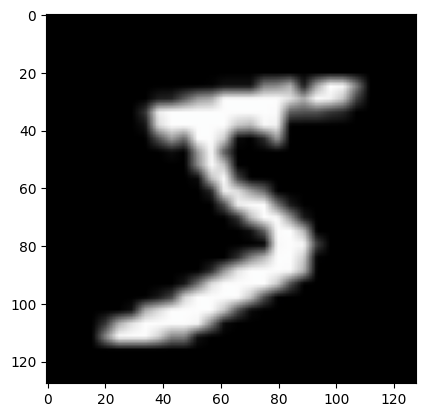

In [ ]:

image = back_to_image(mnist_trainvalset[0][0])

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

normalized_image = (image - mean) / std
print("normalized_image",normalized_image)

print(image.shape)
# metto cmap=gray perchè abbiamo un solo canale
plt.imshow(image,cmap='gray')

plt.show()

(128, 128, 3)


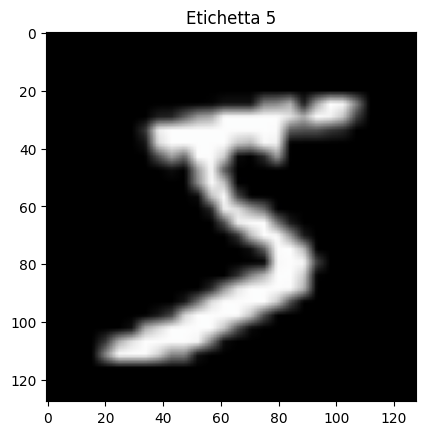

In [ ]:
# Posso fare una funzione
image, label = mnist_trainvalset[0]

image = back_to_image(image)
print(image.shape)
plt.imshow(image,cmap='gray')
plt.title("Etichetta "+str(label))
plt.show()

In [ ]:
classes_label=['0','1','2','3','4','5','6','7','8','9']
labels_all = []
for _, label in mnist_trainvalset:
    labels_all.append(label)

# labels_array = np.array(labels).unique()
# labels_array
labels = set(labels_all)
labels

{0, 1, 2, 3, 4, 5, 6, 7, 8, 9}

**A cosa serve tight_layout() di Matplotlib** <br>
La funzione tight_layout di Matplotlib è utilizzata per ottimizzare automaticamente il layout delle figure. Spesso, quando si creano plot con Matplotlib, gli elementi del grafico (come etichette degli assi, titoli, e tick labels) possono sovrapporsi o essere tagliati, specialmente in figure con più subplot. tight_layout cerca di ridurre queste sovrapposizioni e di migliorare la leggibilità del grafico.

Ecco come funziona tight_layout:

Regolazione automatica: tight_layout calcola automaticamente le spaziature tra i subplot e i bordi della figura per garantire che tutti gli elementi siano visibili e non sovrapposti.
Esecuzione semplice: Si usa solitamente alla fine della creazione di una figura, prima di visualizzarla con plt.show(). Basta chiamare plt.tight_layout() senza parametri per ottenere un miglioramento del layout.
Parametri opzionali: Anche se può essere utilizzata senza parametri, tight_layout accetta diversi argomenti per personalizzare ulteriormente il layout, come pad (spazio aggiuntivo tra i subplot), w_pad e h_pad (spaziature orizzontali e verticali, rispettivamente), e rect (una lista che specifica la posizione della figura).

In [ ]:
iteration = 0

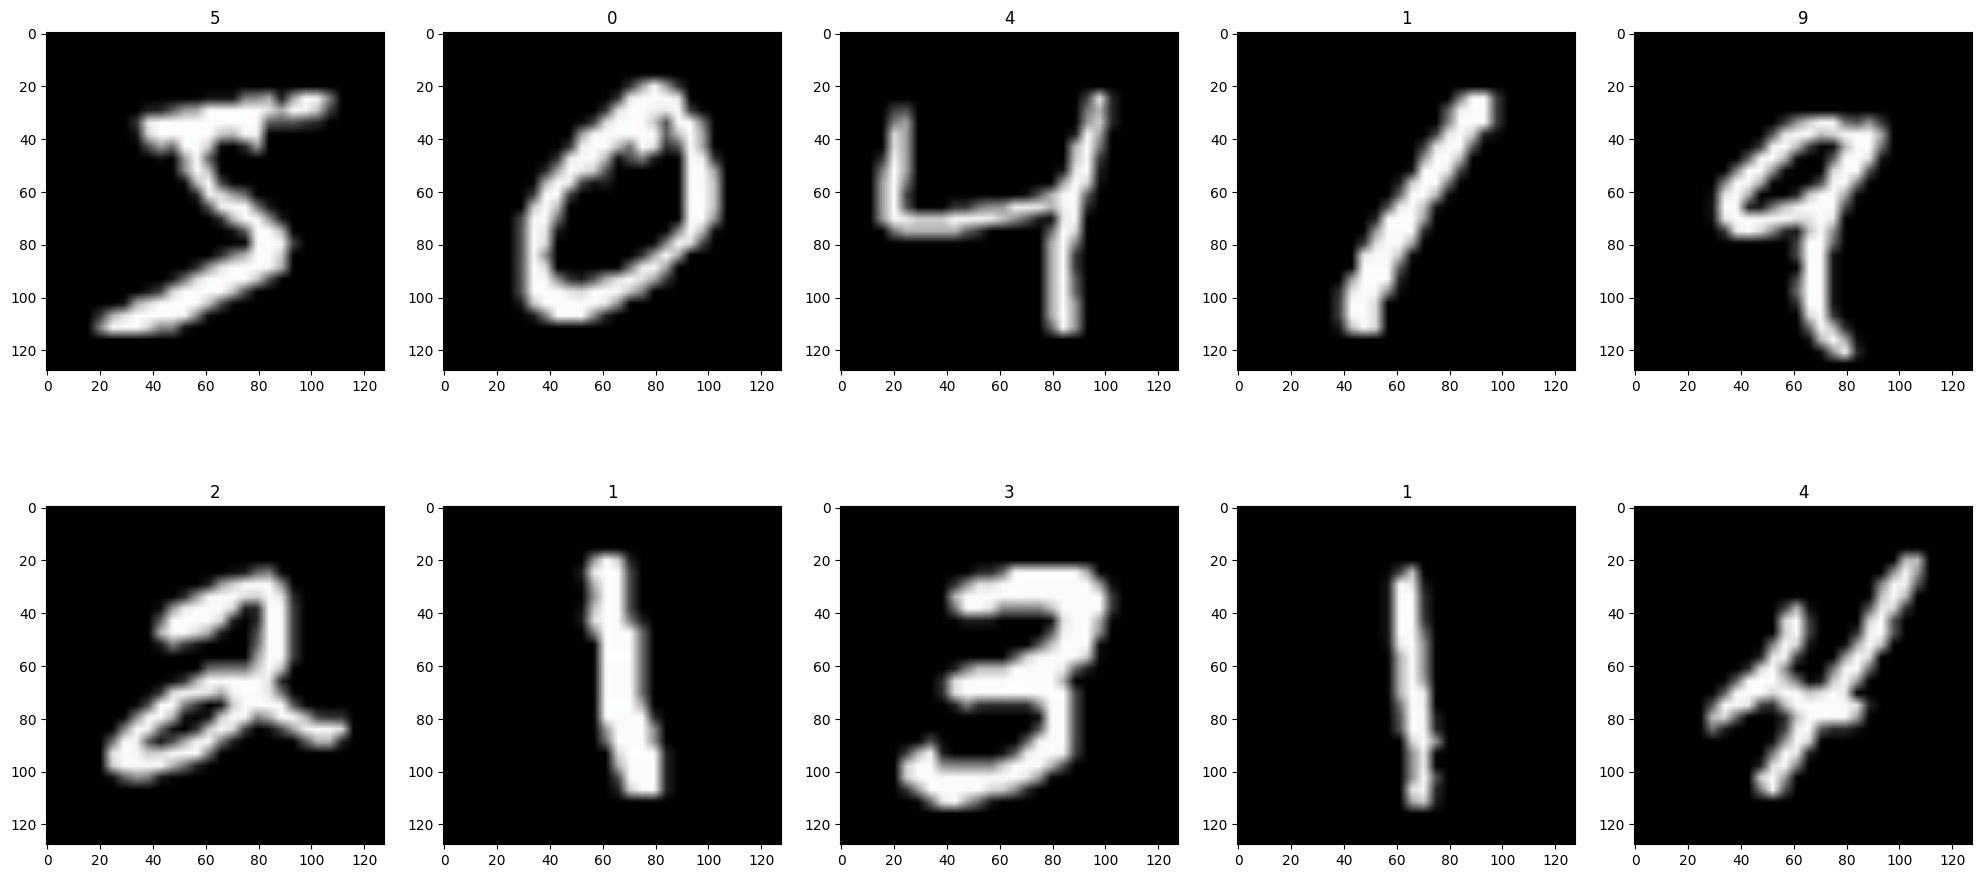

In [ ]:
# Visualizzo 10 numeri alla volta per ripartire da capo
# bisogna reinizializzare la variabile iteration
# Inspect the data
# Visualizzo le immagini in una griglia 2x5
# quindi 10 immagini su 2 righe e 5 colonne
num_row = 2
num_col = 5
# Per ogni griglia 2x5 stampo un subplots della singola immagine
# con la sua figsize 20x10
fig, axes = plt.subplots(num_row, num_col, figsize=(10*num_row,2*num_col))
# itero da 0 a 9 quindi stampo 10 elementi alla volta
# alla prima esecuzione carico le immagini da 0 a 9
# ma alla seconda grazie alla variabile iteration
# visualizzo da 10 a 19 e così via.
for i in range(num_row*num_col):
    # seleziono l'asse prendendo il resto e la
    # divisione con numero assoluto(non chiaro!!)
    # e' un modo semplice per iterare prima su riga poi su colonna
    ax = axes[i//num_col, i%num_col]
    ax.imshow(back_to_image(mnist_trainvalset[iteration * num_row * num_col + i][0]),cmap='gray')
    # Visualizzo la classe che corrisponde all'immagine
    ax.set_title('{}'.format(int(mnist_trainvalset[iteration * num_row * num_col + i][1])))
plt.tight_layout() #
plt.show()
# Eseguendo più volte il codice carico
# sempre nuove immagini
iteration += 1

**BASELINE REGRESSIONE LOGISTICA** <br>

LogisticRegression di scikit-learn si aspetta normalmente una matrice bidimensionale: (numero_campioni, numero_feature). <br>
Quindi, prima ancora di discutere la RAM,
dobbiamo capire che cosa rappresenta ogni campione per il classificatore. <br>

Un'immagine RGB di dimensione 128×128 contiene tre canali. Volendo utilizzare ogni valore dei pixel come feature, quante feature avrà una singola immagine dopo averla appiattita? <br>
Un'immagine RGB di dimensione 128×128 contiene tre canali. Volendo utilizzare ogni valore dei pixel come feature, quante feature avrà una singola immagine dopo averla appiattita?  <br>
3x128x128=49152 perche le feature sono replicate sui tre canali quindi 49152  <br>


Ti propongo di ragionare su tre livelli: <br>

Attenzione alla RAM: il percorso a 28×28 riduce notevolmente la memoria rispetto a 128×128,
ma Logistic Regression può comunque richiedere memoria aggiuntiva durante l'addestramento.  <br>
Se necessario, valutare anche solver, regolarizzazione e una rappresentazione ancora più compatta. <br>

Il punto fondamentale è che possiamo mantenere le immagini a tre canali e 128×128 per DenseNet121,
usando una rappresentazione separata e più leggera per Logistic Regression.<br>


Dato originale: tensore PyTorch con quattro dimensioni. BATCH, CANALI , H , W <br>
Dato appiattito: matrice con 54.000 righe e 49.152 colonne. <br>
Modello: LogisticRegression, che durante il fit può richiedere
ulteriore memoria per le sue elaborazioni. <br>
l numero di elementi è: 54000x49152x4 byte ogni elemento un numero molto alto <br>

la matrice X_train in input al metodo fit
contiene circa  54000x49152=2,65 miliardi di valori.  <br>
Ma questo significa che la memoria necessaria è molto maggiore di quanto possa sembrare inizialmente. <br>

MNIST originale 1x28x28 = 784 <br>
MNIST modificato 3x128x128 = 49152 <br>

Posso utilizzare due diversi transform uno per il DenseNet e uno per per LogisticRegression rappresentando le immagini con 28x28 per LR e lasciare 3x128x128 solo per DenseNet


13:38:47 - INFO - [run_train_lr] - Accuratezza di test (Logistic Regression): 0.9244
13:38:47 - INFO - [lr_analyze] - LogisticRegression: fit 102.5s, n_iter 265, val acc 0.9215
13:38:47 - INFO - [lr_analyze] - [OK] LogisticRegression: ConvergenceWarning=False
13:38:47 - INFO - [lr_analyze] - [OK] LogisticRegression: validation accuracy 0.9215 (expected ~0.92, range 0.9-0.94)
13:38:47 - INFO - [lr_analyze] - [OK] LogisticRegression: logit = sum(w*x)+b exactly (max error 0.0e+00)
13:38:47 - INFO - [lr_analyze] - [OK] LogisticRegression: classes_ == 0..9 (coefficient rows aligned)
13:38:47 - INFO - [lr_analyze] - [OK] LogisticRegression: per-pixel sum of coefficients over classes max 1.8e-13 (~0 with L2: relative and absolute coefficients coincide)
13:38:47 - INFO - [lr_analyze] - [INFO] LogisticRegression: warning raised -> DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.


  figure saved: output_lr/phase0_lr_global_maps.png


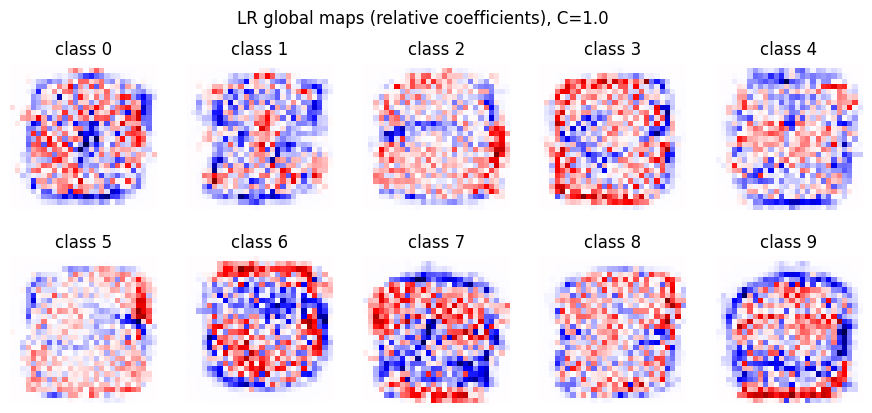

              precision    recall  f1-score   support

           0     0.9523    0.9786    0.9653       980
           1     0.9612    0.9824    0.9717      1135
           2     0.9302    0.8915    0.9104      1032
           3     0.8994    0.9119    0.9056      1010
           4     0.9330    0.9358    0.9344       982
           5     0.8981    0.8700    0.8838       892
           6     0.9421    0.9509    0.9465       958
           7     0.9302    0.9202    0.9252      1028
           8     0.8767    0.8758    0.8762       974
           9     0.9112    0.9158    0.9135      1009

    accuracy                         0.9244     10000
   macro avg     0.9235    0.9233    0.9233     10000
weighted avg     0.9242    0.9244    0.9242     10000



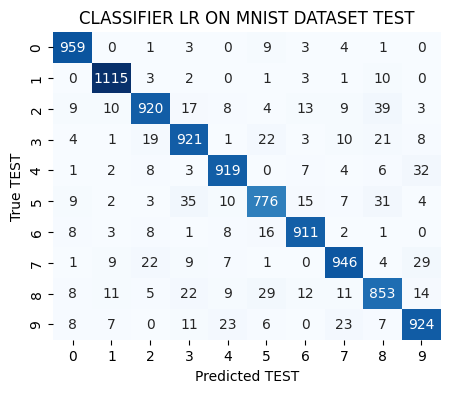

In [ ]:
run_train_lr()

In [ ]:

from IPython.display import Markdown, display

data = {
    'Cifra': ['8', '5', '2', '3'],
    'precision': [0.8767, 0.8981, 0.9302, 0.8994],
    'recall': [0.8758, 0.8700, 0.8915, 0.9119],
    'f1-score': [0.8762, 0.8838, 0.9104, 0.9056],
    'support': [974, 892, 1032, 1010]
}

df = pd.DataFrame(data)
df.set_index('Cifra', inplace=True)

# Support indica il numero effettivo di campioni (istanze) valutate per ogni classe.
display(Markdown(df.to_markdown()))

|   Cifra |   precision |   recall |   f1-score |   support |
|--------:|------------:|---------:|-----------:|----------:|
|       8 |      0.8767 |   0.8758 |     0.8762 |       974 |
|       5 |      0.8981 |   0.87   |     0.8838 |       892 |
|       2 |      0.9302 |   0.8915 |     0.9104 |      1032 |
|       3 |      0.8994 |   0.9119 |     0.9056 |      1010 |

#**CONCLUSIONE SULLA REGRESSIONE LOGISTICA** <br>

1. Il grafico visualizza i coefficienti appresi dalla regressione logistica applicata alle immagini e mostra per ciascuna delle 10 classi, quali pixel contribuiscono maggiormente a distinguere quella cifra dalle altre. <br>

Blu     Coefficienti negativi: valori inferiori alla media delle classi per quel pixel.
Bianco  Coefficienti vicini a zero: coefficienti vicini alla media delle classi per quel pixel.
Rosso   Coefficienti  positivi: valori superiori alla media delle classi per quel pixel.  <br>

Le cifre sono rappresentate diversamente per cui
ogni grafico può avere una scala cromatica diversa.
Perciò, un rosso intenso in una classe non indica necessariamente un coefficiente dello stesso valore
di un rosso intenso in un'altra classe.
Il grafico è interessante perché permette di osservare come la regressione logistica
costruisce una rappresentazione dei pixel utili a distinguere le diverse cifre.  <br>


2. Il classification report misura le prestazioni del modello per ciascuna classe, per esempio attraverso precision, recall e F1-score. <br>

3. La confusion matrix visualizza in diagonale le previsioni corrette e fuori dalla diagonale gli errori del modello. <br>


4. Le classi peggiori , in cui almeno una metrica non supera il 90% ordinate dal peggiore al migliore secondo F1_SCORE sono 8,5,3 e 2<br>

5. Dalla confusion matrix si capisce molto bene quali classe entrano in conflitto: <br>

   5.1. Innanzitutto le classi (2,3,5,8) con le metriche peggiori  si confondono tra loro.<br>
   In aggiunta <br>
   In corrispondenza dei digit 7 e 9 abbiamo 29 errori <br>
   In corrispondenza dei digit 7 e 2 abbiamo 22 errori <br>
   In corrispondenza dei digit 9 e 4 abbiamo 32 errori <br>

   5.2. Il top scorer come errori sono la confusione tra 2 e 8 (39 errori) e il secondo 5 con 3 (35 errori) <br>

6. Promemoria su Precision e Recall <br>

Precision: tra tutte le immagini predette per ogni classe , quante sono corrette? <br>

Recall (sensibilità) : tra tutte le immagini reali , quante vengono riconosciute? <br>

F1-score: un unico indicatore che combina precision e recall tramite la loro media armonica.


#**COMMENTO PER LA RELAZIONE FINALE** <br>

Il grafico rappresenta le mappe globali dei coefficienti relativi appresi dal classificatore Logistic Regression per le dieci classi di cifre, dalla classe 0 alla classe 9. Per ogni classe, i coefficienti vengono riportati alla forma bidimensionale dell'immagine e visualizzati mediante una mappa cromatica.

I coefficienti relativi sono calcolati sottraendo a ciascun coefficiente la media dei coefficienti corrispondenti allo stesso pixel su tutte le classi. In questo modo è possibile evidenziare le differenze tra i pesi associati a una determinata classe e quelli medi delle altre classi.

Il rosso rappresenta coefficienti relativi positivi, mentre il blu rappresenta coefficienti relativi negativi. Il bianco indica valori prossimi a zero. Le aree colorate evidenziano quindi le posizioni dei pixel per cui i coefficienti della classe si discostano maggiormente dalla media.

Le mappe mostrano che le diverse classi presentano distribuzioni differenti dei coefficienti, coerentemente con il fatto che il modello deve distinguere cifre con forme e tratti diversi. Tuttavia, i colori non indicano direttamente la probabilità di classificazione corretta, né consentono da soli di stabilire quali classi siano riconosciute peggio.

Il classification report evidenzia prestazioni inferiori per le classi 8, 5, 3 e 2, tale risultato deve essere interpretato congiuntamente alla matrice di confusione. Quest'ultima permette di identificare le cifre che vengono scambiate più frequentemente e di approfondire le possibili cause degli errori.

In conclusione, le mappe dei coefficienti costituiscono uno strumento di interpretabilità del modello, mentre il classification report e la matrice di confusione sono necessari per valutarne quantitativamente le prestazioni.










#**Importa un modello DenseNet da torchvision** <br>
[Documentazione](https://pytorch.org/hub/pytorch_vision_densenet/) <br>
**Descrizione Modello nella documentazione** <br>

Dense Convolutional Network (DenseNet), connects each layer to every other layer in a feed-forward fashion. Whereas traditional convolutional networks with L layers have L connections – one between each layer and its subsequent layer – our network has L(L+1)/2 direct connections. <br>
For each layer, the feature-maps of all preceding layers are used as inputs, and its own feature-maps are used as inputs into all subsequent layers. DenseNets have several compelling advantages: they alleviate the vanishing-gradient problem, strengthen feature propagation, encourage feature reuse, and substantially reduce the number of parameters <br>

**Dati utilizzati dal modello**<br>

All pre-trained models expect input images normalized in the same way, i.e. mini-batches of 3-channel RGB images of shape (3 x H x W), where H and W are expected to be at least 224. The images have to be loaded in to a range of [0, 1] and then normalized using mean = [0.485, 0.456, 0.406] and std = [0.229, 0.224, 0.225].















**DEFINISCO LA CLASSE DEL MODELLO DI RETE CONV DA ADDESTRARE** <br>

### Dimensione in input/output
Input: $N$, $C_{in}$, H, W  \\
Layer Convoluzionali: $[N, n\_filters, H- (Kernel\_size -1), W-(Kernel\_size -1)]$ \\
Max Pool 2d: Output: $[N, C_{in}, \frac{H}{2}, \frac{W}{2}]$

### Parameteri

Layer Convoluzionali: $(((Kernel_{w} * Kernel_{h})*n_{canali})+1)*n_{filtri}$ \\
Layer lineari : $(input + 1) * output$ \\
Max Pool 2d: 0

#**Trasformazioni per il dataset** <br>


#**ARCHITETTURA DEL MODELLO XAI di tipo DenseNet Modificato** <br>

Partiamo dal modello DensNet addestrato su imagenet e facciamo le seguenti modifiche alla struttura : <br>


1. **Modifica il numero di classi dell'ultimo layer**
Trasformiamo quella rete in una rete che vada per ImageNet per questo tagliamo via l'ultimo strato di classificazione come si dovrà fare anche nel progetto finale che lavora con il Mnist.(dataset di cifre) e lo facciamo uscire invece che con il numero di classi di ImageNet con il numero di classi di LabelFaceINtheWild <br>

2. **Freeziamo tutti i parametri della rete in modo che non siano modificati dal nostro train**. <br>
Facciano transferLearning ovvero scarichiamo il modello DenseNet e usianmo i suoi parametri freezati perchè l'assunto è che pur essendo stato addestrato su un altro dataset potrebbe aver imparato qualcosa d'interessante su cosa e come vedere. Il modello è stato addestrato su ImageNet ma io lo voglio riaddestrare sul nostro dataset . <br>
Il modello viene tagliato a partire dall'ultimo strato convolutivo e verrà addestrato a imparare a classificare sul LabelFaceInTheWildPeople <br>
Per velocizzare il tutto tengo buoni i primi strati convolutivi originali del DenseNet che sono freezati non verranno addestrati e modificati tranne l'ultimo strato aggiunto da noi<br>

**APPUNTI INTERPRETAZIONE DEL CODICE** <br>
**1. DIMENSIONI DEI TENSORI IN INPUT** <br>

Il valore 1024 viene dall’architettura della DenseNet121 pre-addestrata, non dai pixel dell’immagine.

Quando dai alla DenseNet un tensore 3 × 128 × 128, l’immagine attraversa molti layer convoluzionali, pooling e dense blocks. A ogni passaggio le dimensioni spaziali (altezza × larghezza) vengono ridotte, mentre il numero di canali/feature viene trasformato e aumentato. Alla fine, la rete fa una sintesi delle feature visive e restituisce un vettore di dimensione fissa pari a 1024.

In forma semplificata:

3 × 128 × 128
      ↓
Convoluzioni e Dense Blocks
      ↓
Mappe di feature interne
      ↓
Global Average Pooling
      ↓
Vettore di 1024 feature
      ↓
Linear(1024, 10)
Il Global Average Pooling è il passaggio chiave: prende ciascuna mappa di feature finale e ne calcola una sintesi, normalmente una media. Se alla fine il backbone ha 1024 mappe di feature, il pooling produce un numero per ciascuna mappa, quindi un vettore di 1024 valori.

Per questo, il layer originale della DenseNet aveva una struttura concettuale simile a:

nn.Linear(1024, 1000)
per classificare le 1000 classi di ImageNet. Tu lo hai sostituito con:

nn.Linear(1024, 10)
per classificare le 10 cifre di MNIST. Hai cambiato solo il numero di output, mentre le 1024 feature in ingresso al classificatore sono determinate dal backbone DenseNet121.

Un punto utile: grazie al pooling finale, lo stesso backbone può spesso elaborare immagini con dimensioni spaziali differenti, purché sufficientemente grandi e compatibili con l’architettura. Il vettore finale rimane comunque lungo 1024.

**2. INTERPRETAZIONE DEI VALORI IN OUTPUT** <br>

Francesco. I 10 valori in uscita dal layer Linear(1024, 10) corrispondono effettivamente alle 10 classi MNIST, da 0 a 9.

La precisazione importante è questa: l’output diretto del modello non è ancora la probabilità di ogni classe, ma un insieme di logits.

Per esempio, il modello potrebbe produrre:

[-1.2, 0.4, 3.8, 0.1, -0.7, 1.0, -2.3, 0.5, 0.9, -0.4]
il primo valore è lo score associato alla classe 0;
il secondo alla classe 1;
...
il decimo alla classe 9.
Lo score più alto è 3.8, che si trova in posizione 2: la classe predetta è quindi la cifra 2.

Quando usi:

_, predicted_ = torch.max(outputs_, dim=1)
stai estraendo l’indice del logit più alto, cioè la classe scelta dal modello.

Se volessi interpretare quei valori come probabilità, dovresti applicare softmax: trasforma i 10 logits in valori compresi tra 0 e 1 la cui somma è 1. Ad esempio:

Classe 0 → 0,01
Classe 1 → 0,03
Classe 2 → 0,79
...
Con CrossEntropyLoss, però, non devi applicare softmax manualmente durante il training: la loss riceve direttamente i logits e include internamente il passaggio necessario, in modo numericamente stabile.

La scelta della classe resta identica sia usando logits sia usando probabilità softmax, perché softmax mantiene l’ordine dei valori: il valore più grande resta quello della classe predetta.

Nel tuo test, per calcolare accuracy e confusion matrix, ti bastano gli indici predetti ottenuti con torch.max: non serve calcolare le probabilità.

Quale informazione aggiuntiva potresti ottenere dalle probabilità softmax, oltre alla classe predetta


**TRAIN PRODUZIONE CON 5 EPOCHE** <br>


1- Creo la rete e la sposto su Gpu con il metodo to()
1. Setup del modello e dataset
2. Carichiamo DenseNet pre-addestrato

14:16:44 - INFO - [check_model_params] - [build_densenet] Parametri totali: 6,964,106
14:16:44 - INFO - [check_model_params] - [build_densenet] Parametri congelati: 6,953,856
14:16:44 - INFO - [check_model_params] - [build_densenet] Parametri addestrabili: 10,250
14:16:44 - INFO - [get_model] -   NOTE: no checkpoint found 
14:18:23 - INFO - [run_train_cnn] - ATTENZIONE!! Accuratezza(DenseNet Cnn) Non Supera la Soglia(0.95): 0.9495
14:18:23 - INFO - [run_train_cnn] - [Epoca 1, Ciclo   844] train time: 88.944  val time: 9.994 
14:20:03 - INFO - [run_train_cnn] - [Epoca 2, Ciclo   844] train time: 89.967  val time: 9.833 
14:21:42 - INFO - [run_train_cnn] - [Epoca 3, Ciclo   844] train time: 89.057  val time: 9.803 
14:23:20 - INFO - [run_train_cnn] - [Epoca 4, Ciclo   844] train time: 88.316  val time: 9.979 
14:24:59 - INFO - [run_train_cnn] - [Epoca 5, Ciclo   844] train time: 89.093  val time: 9.876 
14:24:59 - INFO - [run_train_cnn] - Train completato
14:25:15 - INFO - [run_main_cnn]

              precision    recall  f1-score   support

           0     0.9888    0.9878    0.9883       980
           1     0.9869    0.9956    0.9912      1135
           2     0.9132    0.9787    0.9448      1032
           3     0.9715    0.9436    0.9573      1010
           4     0.9806    0.9776    0.9791       982
           5     0.9254    0.9462    0.9357       892
           6     0.9779    0.9708    0.9743       958
           7     0.9840    0.9601    0.9719      1028
           8     0.9844    0.9692    0.9767       974
           9     0.9797    0.9564    0.9679      1009

    accuracy                         0.9691     10000
   macro avg     0.9692    0.9686    0.9687     10000
weighted avg     0.9697    0.9691    0.9692     10000



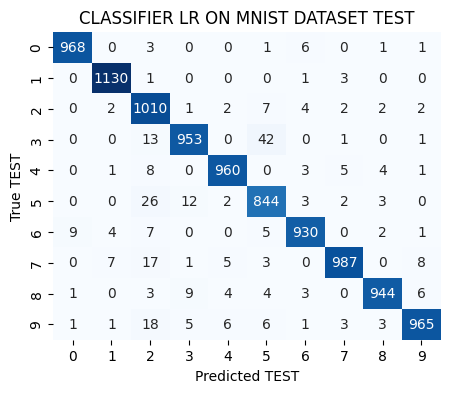

In [ ]:
num_epochs=CONFIG.NUM_EPOCHS
model_cnn = run_main_cnn(CONFIG,num_epochs_=num_epochs)
# 08:09:46 - INFO - [run_main_cnn] - Accuratezza di test (DenseNet Cnn): 0.9496
# 08:02:54 - INFO - [run_main_cnn] - Accuratezza di test (DenseNet Cnn): 0.9489
# RISULTATO CON FLAG BATCHNORM EVAL TRUE
# 08:13:23 - INFO - [run_main_cnn] - Accuratezza di test (DenseNet Cnn): 0.9732
# RISULTATO CON FLAG BATCHNORM EVAL TRUE e RELUINPLACE TRUE
# 08:30:57 - INFO - [run_main_cnn] - Accuratezza di test (DenseNet Cnn): 0.9732

In [ ]:
from IPython.display import Markdown, display

data_1 = {
    'Cifra': ['2', '3','5'],
    'precision': [0.9132, 0.9715, 0.9254 ],
    'recall': [ 0.9787,  0.9436, 0.9462 ],
    'f1-score': [0.9448, 0.9767, 0.9357],
    'support': [1028, 974, 1009]
}


df_1 = pd.DataFrame(data_1)
df_1.set_index('Cifra', inplace=True)

# Support indica il numero effettivo di campioni (istanze) valutate per ogni classe.
display(Markdown(df_1.to_markdown()))


|   Cifra |   precision |   recall |   f1-score |   support |
|--------:|------------:|---------:|-----------:|----------:|
|       2 |      0.9132 |   0.9787 |     0.9448 |      1028 |
|       3 |      0.9715 |   0.9436 |     0.9767 |       974 |
|       5 |      0.9254 |   0.9462 |     0.9357 |      1009 |

#**CONCLUSIONE SUL MODELLO DENSENET** <br>

1. **Metriche** <br>
   Analizziamo le classi in cui almeno una metrica non supera il 95% ordinate dal peggiore al migliore secondo F1_SCORE: <br>
   
   Come se vede le classi peggiori sono le cifre 2 , 3 e 5 e poi in secondo ordine d'importanza 7 e 8 e 9 con almeno una metrica sotto il 97% però non lo considero nel DataFrame <br>
   La classe di cifre '5' è la peggiore in assoluto perchè peggiore in entrambi i modelli <br>

2. **Matrice di Confusione** <br>
   Dalla confusion matrix si capisce molto bene quali classe entrano in conflitto: <br>

   5.1. Innanzitutto le classi (2,3,5) con le metriche peggiori  si confondono tra loro ma non tanto come nella Regressione Logistica .<br>
   In aggiunta <br>
   In corrispondenza dei digit 7 e 2 abbiamo 17 errori <br>
   In corrispondenza dei digit 9 e 2 abbiamo 18 errori <br>
   La rete migliora notevolmente rispetto alla Regressione Logistica in corrispondenza del digit 8 . <br>

   5.2. Il top scorer come errori sono la confusione tra  3 e 5 (42 errori con lr erano 35 ) e il secondo 5 con 2 (26 errori con le erano solo 3) <br>


**CARICO I PESI DEL MODELLO PER NON RIFARE IL TRAIN**
oppure il carico pesi e optimizer salvati prima

In [ ]:
model  = get_model(CONFIG)
# model

15:02:21 - INFO - [check_model_params] - [build_densenet] Parametri totali: 6,964,106
15:02:21 - INFO - [check_model_params] - [build_densenet] Parametri congelati: 6,953,856
15:02:21 - INFO - [check_model_params] - [build_densenet] Parametri addestrabili: 10,250
15:02:22 - INFO - [check_model_params] - [build_densenet] Parametri totali: 6,964,106
15:02:22 - INFO - [check_model_params] - [build_densenet] Parametri congelati: 6,953,856
15:02:22 - INFO - [check_model_params] - [build_densenet] Parametri addestrabili: 10,250
15:02:22 - INFO - [get_model] -   NOTE: yes checkpoint found 


**CARICO LISTE DI IMMAGINI DOVE I MODELLI SBAGLIANO E DOVE NON SBAGLIANO**

In [ ]:
def run_create_list_images_from_eval( X_test_ , y_test_,y_pred_ , list_class_, n_images_=100):
    if not list_class_:
        raise ValueError("list_class non può essere vuota")
    else:
        # n_per_class = n_images // len(list_class)
        n_per_class = max(1, n_images_ // len(list_class_))

    # Maschere su tutte le classi
    correct_mask = y_pred_ == y_test_
    wrong_mask = y_pred_ != y_test_
    # logger.info(f" correct_mask {correct_mask.size()} wrong_mask {wrong_mask.size()}")
    logger.info(f" correct_mask {correct_mask} wrong_mask {wrong_mask}")

    list_images_lr_ok = []
    list_images_lr_ko = []

    logger.info(f" y_test_ {y_test_}")
    logger.info(f" y_test_ {type(y_test_)}")

    # print("--- DEBUG TIPI E VALORI ---")
    # print("Tipo di y_test_:", type(y_test_))
    # print("Forma (shape) di y_test_:", y_test_.shape if hasattr(y_test_, 'shape') else "N/A")
    # print("Tipo dei dati in y_test_:", y_test_.dtype if hasattr(y_test_, 'dtype') else "N/A")
    # print("Primi 5 elementi di y_test_:", y_test_[:5])
    # print("-" * 30)
    for id_class in list_class_:
        logger.info(f" start classe {id_class}")

        class_mask = y_test_ == id_class
        logger.info(f" total_class_mask {class_mask}")

        class_ok_mask = class_mask & correct_mask
        class_ko_mask = class_mask & wrong_mask

        # logger.info(f" class_ok_mask value {type(class_ok_mask)}")
        # logger.info(f" class_ko_mask value {type(class_ko_mask)}")

        # indici delle maschere in modo che il valore
        # sia utilizzabile
        class_ok_mask = torch.as_tensor(class_ok_mask).cpu().numpy()
        class_ko_mask = torch.as_tensor(class_ko_mask).cpu().numpy()

        # logger.info(f" class_ko_mask value {class_ko_mask}")
        # idx_ok = np.where(class_ok_mask)[0]
        # idx_ko = np.where(class_ko_mask)[0]

        # idx_ok = np.where(class_ok_mask.numpy())[0]
        # idx_ko = np.where(class_ko_mask.numpy())[0]

        # converte in un vettore se le variabili sono composte da un solo valore
        # [0] finale è necessario perchè np.where ritorna una tupla
        # atleast_1d garantisce che il risultato abbia almeno una dimensione.
        idx_ok_old = np.where(np.atleast_1d(class_ok_mask))[0]
        idx_ko_old = np.where(np.atleast_1d(class_ko_mask))[0]

        idx_ko = np.where((np.asarray(y_test_) == id_class) &
                          (np.asarray(y_test_) != np.asarray(y_pred_)))[0]

        idx_ok = np.where((np.asarray(y_test_) == id_class) &
                          (np.asarray(y_test_) == np.asarray(y_pred_)))[0]

        logger.info(f"Indici KO di controllo: {idx_ko[:10]}")
        logger.info(f"Indici OK di controllo: {idx_ok[:10]}")

        # Queste due variabili stabiliscono già quanti errori e quante
        # immagini corrette possiamo selezionare
        # n_ko non può superare né il numero di errori disponibili né il limite per classe.
        n_ko = min(len(idx_ko), n_per_class)

        # n_ok utilizza soltanto i posti rimasti dopo aver selezionato gli errori.
        n_ok = min(len(idx_ok), n_per_class - n_ko)

        logger.info(f" n_ko {n_ko}")
        logger.info(f" n_ok {n_ok}")

        idx_ko_selected = idx_ko[:n_ko]
        idx_ok_selected = idx_ok[:n_ok]

        for i in (idx_ok_selected):

            # CNN:In questo modo se è un immagine che deriva dalla cnn
            # con 3 dimensioni ma la prima è uguale a 1 relativa a 1x28x28
            # toglie la prima dimensione ininfluente
            # LR: il codice rimane quasi identico al precedente
            img_to_save = X_test_[i]
            if img_to_save.ndim == 3 and img_to_save.shape[0] == 1:
                img_to_save = img_to_save.squeeze(0) # Rimuove la dimensione del canale se è 1

            # Adatto il dizionario al formato json
            # dict_curr_ok = { "image": X_test_[i].tolist() if hasattr(X_test_[i], 'tolist') else list(X_test_[i]),
            dict_curr_ok = { "image": img_to_save.tolist() ,
                              "y_true": int(y_test_[i]) if not hasattr(y_test_[i], 'item') else y_test_[i].item(),
                              "y_pred": int(y_pred_[i]) if not hasattr(y_pred_[i], 'item') else y_pred_[i].item()
                            }

            list_images_lr_ok.append(dict_curr_ok)

        # print("Indici KO selezionati:", idx_ko_selected)

        for i in (idx_ko_selected):
            # if y_test_[i] != y_pred_[i]:
            #     print(f"i={i}, "f"classe richiesta={id_class}, "
            #           f"y_true={y_test_[i]}, "
            #           f"y_pred={y_pred_[i]}"
            #           )

            # CNN:In questo modo se è un immagine che deriva dalla cnn
            # con 3 dimensioni ma la prima è uguale a 1 relativa a 1x28x28
            # toglie la prima dimensione ininfluente
            # LR: il codice rimane quasi identico al precedente
            img_to_save = X_test_[i]
            if img_to_save.ndim == 3 and img_to_save.shape[0] == 1:
                img_to_save = img_to_save.squeeze(0) # Rimuove la dimensione del canale se è 1

            # dict_curr_ko = { "image": X_test_[i].tolist() if hasattr(X_test_[i], 'tolist') else list(X_test_[i]),
            dict_curr_ko = { "image": img_to_save.tolist() ,
                              "y_true": int(y_test_[i]) if not hasattr(y_test_[i], 'item') else y_test_[i].item(),
                              "y_pred": int(y_pred_[i]) if not hasattr(y_pred_[i], 'item') else y_pred_[i].item()
                            }

            list_images_lr_ko.append(dict_curr_ko)

        logger.info(f" end classe {id_class}")

    return list_images_lr_ok , list_images_lr_ko

def run_evaluate_lr(list_class, n_images=100):
    """
        Evaluate Regressione Logistica
        Con n_images = 3 e list_class = [2, 3, 5, 8],
        orresti selezionare almeno un'immagine per ciascuna classe, se disponibile.
        Questo significa che potresti restituire 4 immagini anche se ne hai richieste 3.

        con n_images = 10 e 3 classi, la divisione intera assegna 3 posti
        per classe: ne utilizzi al massimo 9, non 10.
        Non è il nostro caso visto che abbiamo 1_images=100 e len(list_class)=4
    """

    if not list_class:
        raise ValueError("list_class non può essere vuota")
    else:
        # n_per_class = n_images // len(list_class)
        n_per_class = max(1, n_images // len(list_class))


    # con n_images = 10 e 3 classi, la divisione intera assegna 3 posti
    # per classe: ne utilizzi al massimo 9, non 10.

    X_train ,X_val, X_test , y_train ,y_val ,  y_test = load_data_lr()
    logger.info(f" X_train numpy {X_train.shape}")
    logger.info(f" X_test numpy {X_test.shape}")

    # lr = LogisticRegression( random_state=SEED,max_iter=max_iter)
    lr , diag = lr_fit_and_diagnose(X_train, y_train, X_val, y_val ,CONFIG)
    y_pred =  lr.predict(X_test)

    logger.info("Indici KO di controllo per classe:")

    for id_class in list_class:
             idx_ko_check = np.where((y_test == id_class) &
                                     (y_test != y_pred)
                                     )[0]

             logger.info(f"Classe {id_class}: {len(idx_ko_check)} errori")

    list_images_lr_ok , list_images_lr_ko  = run_create_list_images_from_eval( X_test,
                                                                                  y_test,
                                                                                  y_pred ,
                                                                                  list_class,
                                                                                  n_images_=100)
    return list_images_lr_ok , list_images_lr_ko

def run_evaluate_cnn( model_ ,
                      device_ ,
                      list_class,
                      n_images=100 ):


    if not list_class:
        raise ValueError("list_class non può essere vuota")
    else:
        # n_per_class = n_images // len(list_class)
        n_per_class = max(1, n_images // len(list_class))


    _ , test_dataset_cnn = load_dataset_cnn()
    test_loader_cnn = DataLoader(test_dataset_cnn, batch_size=BATCH_SIZE,shuffle=False)

    model_ = model_.to(device_)
    model_.eval()
    y_pred_=[]
    y_true_=[]
    X_test_=[]

    list_images_cnn_ok_tot = []
    list_images_cnn_ko_tot = []

    with torch.no_grad():
        for i, (images, labels) in enumerate(test_loader_cnn):
            images, labels = images.to(device_), labels.to(device_)

            # print images gid with relative prevision and ground truth

            # prendo l'output delle previsioni direttamente
            # dalle immagini caricate applicando la nostra rete neurale convolutiva
            # e addestrata .
            outputs_ = model_(images)
            # Ottengo il valore della classe prevista
            # usando le etichette per gli output ottenuti che abbiamo definito come prima.
            _, predicted = torch.max(outputs_, 1)

            X_test_.append(images)
            y_true_.append(labels)
            y_pred_.append(predicted)

    # Concatena tutto l'intero dataset
    X_test_ = torch.cat(X_test_).cpu().numpy()
    y_true_ = torch.cat(y_true_).cpu().numpy()
    y_pred_ = torch.cat(y_pred_).cpu().numpy()

    list_images_cnn_ok , list_images_cnn_ko  = run_create_list_images_from_eval( X_test_,
                                                                                     y_true_,
                                                                                    y_pred_ ,
                                                                                   list_class,
                                                                                    n_images_=n_images)
    logger.info("Indici KO di controllo per classe:")

    for id_class in list_class:
          idx_ko_check = np.where((y_true_ == id_class) &
                                (y_true_ != y_pred_)
                                )[0]

          logger.info(f"Classe {id_class}: {len(idx_ko_check)} errori")



    return list_images_cnn_ok , list_images_cnn_ko

import json
def save_dict_to_json(file_images , data_dict):
    with open(file_images, "w", encoding="utf-8") as f:
        json.dump(data_dict, f, indent=4)

def load_dict_from_json(file_name):
    with open(file_name, "r", encoding="utf-8") as f:
        list_load_dict = json.load(f)

    logger.info(f"Caricati {len(list_load_dict)} elementi con successo!")
    logger.info("Primo elemento:", list_load_dict[0])
    return list_load_dict




In [ ]:
list_images_lr_ok , list_images_lr_ko = run_evaluate_lr(list_class=[2,3,5,8] , n_images=100)

save_dict_to_json("images_lr_ok.json" , list_images_lr_ok)
save_dict_to_json("images_lr_ko.json" , list_images_lr_ko)



16:02:41 - INFO - [run_evaluate_lr] -  X_train numpy (54000, 784)
16:02:41 - INFO - [run_evaluate_lr] -  X_test numpy (10000, 784)
16:04:20 - INFO - [run_evaluate_lr] - Indici KO di controllo per classe:
16:04:20 - INFO - [run_evaluate_lr] - Classe 2: 1032 errori
16:04:20 - INFO - [run_evaluate_lr] - Classe 3: 1010 errori
16:04:20 - INFO - [run_evaluate_lr] - Classe 5: 892 errori
16:04:20 - INFO - [run_evaluate_lr] - Classe 8: 974 errori
16:04:20 - INFO - [run_create_list_images_from_eval] -  correct_mask tensor([True, True, True,  ..., True, True, True]) wrong_mask True
16:04:20 - INFO - [run_create_list_images_from_eval] -  y_test_ tensor([7, 2, 1,  ..., 4, 5, 6])
16:04:20 - INFO - [run_create_list_images_from_eval] -  y_test_ <class 'torch.Tensor'>
16:04:20 - INFO - [run_create_list_images_from_eval] -  start classe 2
16:04:20 - INFO - [run_create_list_images_from_eval] -  total_class_mask tensor([False,  True, False,  ..., False, False, False])
16:04:20 - INFO - [run_create_list_im

In [ ]:
model , _ , _ = get_model(CONFIG)

list_images_cnn_ok , list_images_cnn_ko = run_evaluate_cnn(model ,
                                                          device ,
                                                          list_class=['2','3','5'] ,
                                                           n_images=100)

save_dict_to_json("images_cnn_ok.json" , list_images_cnn_ok)
save_dict_to_json("images_cnn_ko.json" , list_images_cnn_ko)

16:04:56 - INFO - [check_model_params] - [build_densenet] Parametri totali: 6,964,106
16:04:56 - INFO - [check_model_params] - [build_densenet] Parametri congelati: 6,953,856
16:04:56 - INFO - [check_model_params] - [build_densenet] Parametri addestrabili: 10,250
16:04:57 - INFO - [check_model_params] - [build_densenet] Parametri totali: 6,964,106
16:04:57 - INFO - [check_model_params] - [build_densenet] Parametri congelati: 6,953,856
16:04:57 - INFO - [check_model_params] - [build_densenet] Parametri addestrabili: 10,250
16:04:57 - INFO - [get_model] -   NOTE: yes checkpoint found 
16:16:53 - INFO - [run_create_list_images_from_eval] -  correct_mask [ True  True  True ...  True  True  True] wrong_mask [False False False ... False False False]
16:16:53 - INFO - [run_create_list_images_from_eval] -  y_test_ [7 2 1 ... 4 5 6]
16:16:53 - INFO - [run_create_list_images_from_eval] -  y_test_ <class 'numpy.ndarray'>
16:16:53 - INFO - [run_create_list_images_from_eval] -  start classe 2
16:16

**VISUALIZZO UNA GRIGLIA DI IMMAGINI**

09:09:03 - WARNING - [_normalize_image_array] - Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..1.0000000236034394].


10000 immagini, 10 identità
torch.Size([32, 3, 128, 128]) torch.Size([32])


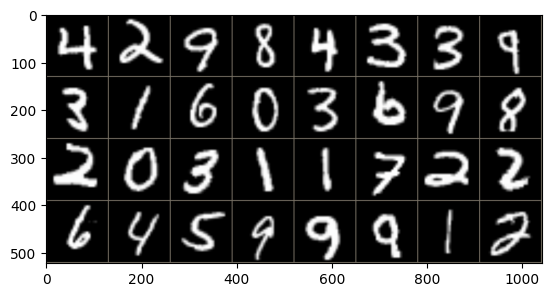

,Ground Truth,Prediction
0,4 - four,2 - two
1,2 - two,2 - two
2,9 - nine,8 - eight
3,8 - eight,8 - eight
4,4 - four,4 - four


In [ ]:
_, mnist_testset_cnn = load_dataset_cnn()
images, labels = get_images_labels(mnist_testset_cnn)
print(images.shape,labels.shape)
df, gt_pred_desc , gt_label_desc , predicted = run_predict_on_image(mnist_testset_cnn,images,labels,model)
df.head()

**VISUALIZZO UNA SINGOLA IMMAGINE**

09:09:20 - WARNING - [_normalize_image_array] - Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..0.9960784730911255].


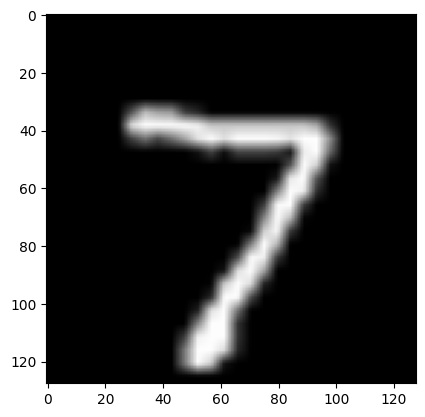

,Ground Truth,Prediction
0,7 - seven,8 - eight


In [ ]:
images, labels = get_images_labels(mnist_testset_cnn,flag_data_loader=False,idx_dataset=0)
df, gt_pred_desc , gt_label_desc , predicted = run_predict_on_image(mnist_testset_cnn,images,labels,model)
df.head()

**SPIEGAZIONE CON CAPTUM**

In [ ]:
mnist_testset_cnn.class_to_idx['0 - zero']
mnist_testset_cnn.class_to_idx.values()

idx_to_class = {v: k for k, v in mnist_testset_cnn.class_to_idx.items()}
key = idx_to_class[int('0')]
key


'0 - zero'

In [ ]:
idx_to_class = {v: k for k, v in mnist_testset_cnn.class_to_idx.items()}
list_to_class = [k for k, v in mnist_testset_cnn.class_to_idx.items()]
key = idx_to_class[int('0')]
keys = idx_to_class.keys()
class_values = ['0','1','2','3','4','5','6','7','8','9']
print(f"idx_to_class {idx_to_class}")
print(f"keys {keys}")
print(f"list_to_class {list_to_class}")

for i in keys:
  print(f"{i}")
  # indices_for_identity = [i for i, (path, label) in enumerate(dataset_.[]) if label == target_class_id]

idx_to_class {0: '0 - zero', 1: '1 - one', 2: '2 - two', 3: '3 - three', 4: '4 - four', 5: '5 - five', 6: '6 - six', 7: '7 - seven', 8: '8 - eight', 9: '9 - nine'}
keys dict_keys([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
list_to_class ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
0
1
2
3
4
5
6
7
8
9


In [ ]:
def get_inference_error_images(dataset_,model_,class_search = '0 - zero'):
    # name_search = "George_W_Bush"
    # name_search = "Farouk_al-Sharaa"
    name_search = "0"
    label = labels[0]
    # name_search = 'Milo_Djukanovic'
    target_class_id = dataset_.class_to_idx[name_search]
    logger.info(f"target_class_id {target_class_id}")
    logger.info(f"target_class_id {label}")

    dataset_.class_to_idx[class_search]
    dataset_.class_to_idx.values()

    idx_to_class = {v: k for k, v in dataset_.class_to_idx.items()}
    key = idx_to_class[int('0')]

    class_values = ['0','1','2','3','4','5','6','7','8','9']
    print(f"idx_to_class {idx_to_class}")
    print(f"key {key}")



    indices_for_identity = [i for i, (path, label) in enumerate(dataset_.samples) if label == target_class_id]
    print(len(indices_for_identity))
    print(indices_for_identity)   # es. [4021, 4022, 4023] — le foto di quella persona

    model.eval()
    # name_search = "Farouk_al-Sharaa"
    name_search = "George_W_Bush"
    img_index_wrong = None
    for i in indices_for_identity:            # solo le foto di Milo_Djukanovic
        img, label = dataset_[i]
        # print(f"i {i} label {label}")
        img_input = img.unsqueeze(0).to(device)
        with torch.no_grad():
            output = model(img_input)
            pred = output.argmax(dim=1).item()
            # trovata la foto che il modello sbaglia
            # if pred != label and i not in (2660,2788,2876) and name_search == dataset.classes[pred]:
            if pred != label and name_search == dataset_.classes[pred]:
                img_index_wrong = i
                predicted_wrong = pred
                break

    # indice di Bush che sbaglia con Farouk
    print(img_index_wrong, dataset_.classes[label], dataset_.classes[predicted_wrong])

**INIZIALIZZO I METODI DI SPIEGAZIONE**

In [ ]:
# 3. Spiegazioni con Captum
def run_inference_on_image(dataset_,model_,face_idx = 0):
    model_.eval()

    input_img, label = dataset_[face_idx]
    print(f"label {label}")
    input_img = input_img.unsqueeze(0).to(device)
    label = torch.tensor([label]).to(device)

    # Ottieni il nome della classe
    class_names = list(dataset_.class_to_idx.keys())
    class_name = class_names[label.item()]

    print(f"Analizziamo l'immagine {face_idx} con etichetta: {class_name}")

    with torch.no_grad():
        output = model_(input_img)
        pred = output.argmax(dim=1).item()
        pred_name = class_names[pred]

        str_title = f'Immagine Originale\nTrue: {class_name}\nPred: {pred_name}'

    print(f"{str_title}")
    return input_img , str_title





def visualize_attributions(orig_img, attributions, title , title_org):
    attr_map = attributions.squeeze().cpu().detach().numpy()
    if len(attr_map.shape) > 2:
        attr_map = np.abs(attr_map).sum(axis=0)  # Somma sui canali

    # Normalizzazione
    attr_map = (attr_map - attr_map.min()) / (attr_map.max() - attr_map.min() + 1e-8)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    # Denormalizziamo l'immagine per la visualizzazione
    img_show = orig_img.squeeze().cpu().detach().numpy()
    img_show = np.transpose(img_show, (1, 2, 0))
    img_show = img_show * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    img_show = np.clip(img_show, 0, 1)

    plt.imshow(img_show)
    # plt.title('Immagine Originale')
    plt.title(title_org)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(attr_map, cmap='hot')
    plt.title(title)
    plt.axis('off')
    plt.colorbar()
    plt.show()



def explain_gradcam(model, x1, target, layer_name, relu=True):
    from captum.attr import LayerGradCam
    layer = dict(model.named_modules())[layer_name]
    att = LayerGradCam(model, layer).attribute(x1, target=int(target), relu_attributions=relu)
    return att[0, 0].detach().cpu().numpy()


def explain_ig(model, x1, target, cfg, steps=None):
    from captum.attr import IntegratedGradients
    att = IntegratedGradients(model).attribute(
        x1, baselines=black_normalized(x1.shape[-1], x1.device), target=int(target),
        n_steps=steps or cfg.IG_STEPS, internal_batch_size=50)
    return att


def explain_saliency(model, x1, target):
    from captum.attr import Saliency
    att = Saliency(model).attribute(x1.clone().requires_grad_(True), target=int(target), abs=True)
    return att[0].sum(0).detach().cpu().numpy()       # sum over channels, >= 0

label 7
Analizziamo l'immagine 0 con etichetta: 7 - seven
Immagine Originale
True: 7 - seven
Pred: 7 - seven


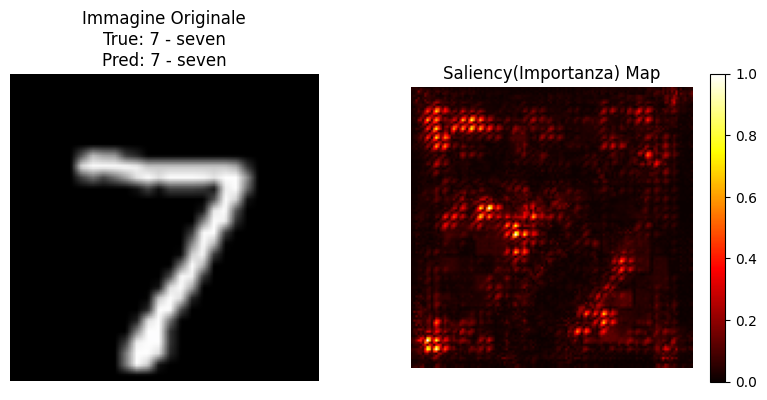

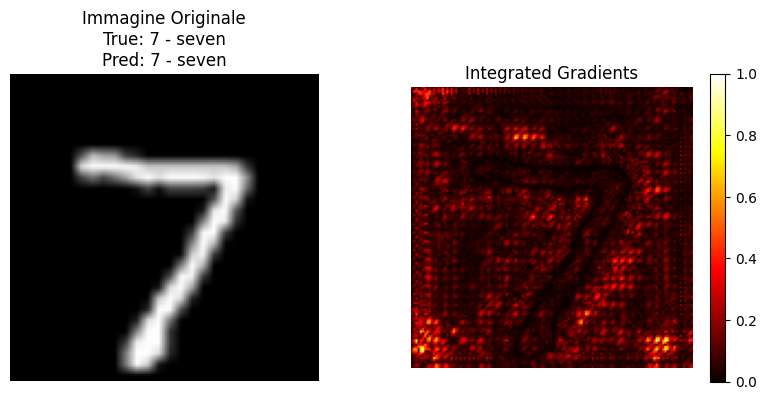

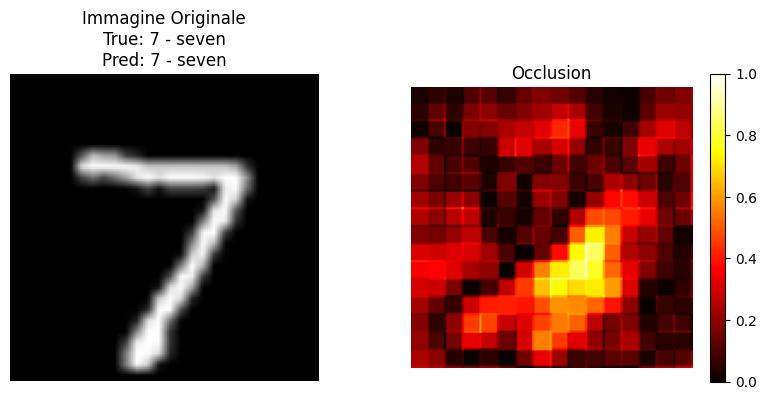

In [ ]:
input_img_org , str_title_org = run_inference_on_image(mnist_testset_cnn,model,face_idx = 0)

# Inizializzazione dei metodi di spiegazione
saliency = Saliency(model)
ig = IntegratedGradients(model)
occlusion = Occlusion(model)

# Calcolo e visualizzazione delle attribuzioni
# Saliency
saliency_attr = saliency.attribute(input_img_org, target=label)
visualize_attributions(input_img_org, saliency_attr, 'Saliency(Importanza) Map',str_title_org)

# Integrated Gradients steps 50 oppure 200 fare dei test comparativi
ig_attr = ig.attribute(input_img_org, target=label, n_steps=CONFIG.IG_STEPS)
visualize_attributions(input_img_org, ig_attr, 'Integrated Gradients', str_title_org)

# Occlusion
o_w, o_s = CONFIG.OCCLUSION_WINDOW, CONFIG.OCCLUSION_STRIDE
o_size = CONFIG.DENSENET_SIZE
ones, zeros = torch.ones(1, 3, o_size, o_size, device=device), torch.zeros(1, 3, o_size, o_size, device=device)
occlusion_attr = occlusion.attribute(input_img_org,
                                   target=label,
                                   strides=(3, o_s, o_s),
                                   sliding_window_shapes=(3,o_w,o_w),
                                   baselines=zeros)
visualize_attributions(input_img_org, occlusion_attr, 'Occlusion', str_title_org)